# Bitcoin Price Forecasting - ARIMA Performance
Forecast Bitcoin closing Price at 1, 3, 5, 7, 14, 21 and 30 calendar days.
Evaluate ARIMA against observed prices using RMSE (USD) and MAPE (%).

Train = first 80%; Test = final 20%, chronological, no validation set.
Order selection and diagnostics use train only. Forecast parameters remain fixed throughout test.

**Run:** select **Python 3.12 (BTC ARIMA)**, then **Restart Kernel and Run All Cells**.
Outputs: `PROJECT_2026/OUTPUT/ARIMA_BTC/{tables,figures,summaries}`.
Dependencies: pandas, numpy, matplotlib, statsmodels, pmdarima, scipy.

Forecast tables show both historical test predictions and future predictions from the latest observed date.


## Configuration & Library Versions


In [1]:
from pathlib import Path
import sys
import json
import warnings
from importlib.metadata import version

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import statsmodels
import pmdarima as pm
import scipy
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from IPython.display import display, Markdown, HTML

HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
TRAIN_RATIO = 0.8
ALPHA = 0.05
DATA_PATH = Path('Bitcoin_Historical_Data.csv')
MAX_P = MAX_Q = 5
EXPECTED_N = 1897

# Support JupyterLab launched from BTC_TEST, project root, or a child directory.
search_dirs = [Path.cwd(), *Path.cwd().parents]
if not DATA_PATH.is_file():
    paths = [base / rel for base in search_dirs for rel in (
        'Bitcoin_Historical_Data.csv', 'BTC_TEST/Bitcoin_Historical_Data.csv',
        'CSV/Bitcoin Historical Data.csv', 'CSV/Bitcoin_Historical_Data.csv')]
    DATA_PATH = next((p for p in paths if p.is_file()), DATA_PATH)
if not DATA_PATH.is_file():
    raise FileNotFoundError('Set DATA_PATH to your Bitcoin_Historical_Data.csv file.')
DATA_PATH = DATA_PATH.resolve()
PROJECT_ROOT = next((base for base in search_dirs
    if (base / 'BTC_TEST').is_dir() and (base / 'CSV').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Launch JupyterLab inside PROJECT_2026 or BTC_TEST.')
OUTPUT_DIR = PROJECT_ROOT / 'OUTPUT' / 'ARIMA_BTC'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIGURE_DIR = OUTPUT_DIR / 'figures'
SUMMARY_DIR = OUTPUT_DIR / 'summaries'
for directory in (TABLE_DIR, FIGURE_DIR, SUMMARY_DIR):
    directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True,
                     'grid.alpha': 0.25, 'figure.dpi': 110})
pd.set_option('display.max_columns', 20)

versions = pd.DataFrame([(m, version(m)) for m in
    ['pandas', 'numpy', 'matplotlib', 'statsmodels', 'pmdarima', 'scipy']],
    columns=['library', 'version'])
print('Python:', sys.version)
display(versions)
print('Data:', DATA_PATH, '\nOutputs:', TABLE_DIR.parent)
versions.to_csv(TABLE_DIR / 'library_versions.csv', index=False)

def save_table(frame, filename):
    frame.to_csv(TABLE_DIR / filename, index=False, encoding='utf-8-sig')

def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def warning_text(items):
    return ' | '.join(dict.fromkeys(str(w.message) for w in items))


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)]


,library,version
0,pandas,2.3.3
1,numpy,2.5.3
2,matplotlib,3.11.1
3,statsmodels,0.15.0
4,pmdarima,2.1.1
5,scipy,1.18.1


Data: C:\Users\User\Desktop\PROJECT_2026\CSV\Bitcoin Historical Data.csv 
Outputs: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\ARIMA_BTC


## Step 1 — Data Preparation
แปลงทุกคอลัมน์จาก string, ตรวจวันซ้ำ/วันหายโดยไม่เติมค่าราคา
แสดง Volume suffix B เพื่อให้ตรวจสอบจากแหล่งข้อมูล โดยเก็บทุกแถวไว้
Volume ไม่เข้าสู่โมเดล และไม่สรุปว่าเป็นข้อมูลผิดจาก suffix เพียงอย่างเดียว


In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str)
required = ['Date', 'Price', 'Open', 'High', 'Low', 'Vol.', 'Change %']
assert set(required).issubset(raw.columns), f'Missing columns: {set(required) - set(raw.columns)}'
assert not raw[required].isna().any().any(), 'Missing raw values'
df = raw[required].copy()
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='raise')
assert not df['Date'].duplicated().any(), 'Duplicate dates'
df = df.sort_values('Date')
for col in ['Price', 'Open', 'High', 'Low']:
    df[col] = pd.to_numeric(df[col].str.replace(',', '', regex=False), errors='raise').astype(float)

vol_text = df['Vol.'].str.strip().str.upper().str.replace(',', '', regex=False)
b_rows = df.loc[vol_text.str.endswith('B')].copy()
parts = vol_text.str.extract(r'^(?P<number>\d+(?:\.\d+)?)(?P<suffix>[KMB]?)$')
assert parts.notna().all().all(), 'Unrecognized volume format'
df['Volume'] = pd.to_numeric(parts['number']) * parts['suffix'].map({'': 1., 'K': 1e3, 'M': 1e6, 'B': 1e9})
b_rows['Volume'] = df.loc[b_rows.index, 'Volume']
print(f'Volume B rows: {len(b_rows)} — retained; inspect against the source.')
display(b_rows)
save_table(b_rows, 'volume_B_rows.csv')
df['Change %'] = pd.to_numeric(df['Change %'].str.replace('%', '', regex=False), errors='raise') / 100
df = df.drop(columns='Vol.').set_index('Date').asfreq('D')
assert df.index.is_unique and df.index.is_monotonic_increasing
assert not df.isna().any().any(), 'Missing values or calendar gaps; do not silently impute'
assert np.isfinite(df.to_numpy()).all()
assert (df['Price'] > 0).all(), 'Log requires strictly positive prices'
assert len(df) == EXPECTED_N
assert df.index[0] == pd.Timestamp('2021-07-01') and df.index[-1] == pd.Timestamp('2026-09-09')
log_price = np.log(df['Price']).rename('log_price')
print(f'Validated {len(df):,} daily observations: {df.index.min().date()} to {df.index.max().date()}')
display(df.head())


Volume B rows: 16 — retained; inspect against the source.


,Date,Price,Open,High,Low,Vol.,Change %,Volume
1650,2022-03-04,39142.7,42463.0,42848.7,38594.9,3.21B,-7.82%,3.210000e+09
1649,2022-03-05,39395.8,39142.8,39600.2,38626.1,1.50B,0.65%,1.500000e+09
1648,2022-03-06,38403.1,39396.3,39668.1,38115.0,1.93B,-2.52%,1.930000e+09
1647,2022-03-07,38024.8,38420.6,39532.0,37182.1,3.02B,-0.99%,3.020000e+09
1646,2022-03-08,38744.8,38020.6,39351.5,37886.6,2.67B,1.89%,2.670000e+09
1645,2022-03-09,41929.0,38731.5,42538.5,38663.3,3.60B,8.22%,3.600000e+09
1644,2022-03-10,39416.3,41933.9,42029.1,38603.5,3.62B,-5.99%,3.620000e+09
1643,2022-03-11,38730.2,39422.5,40177.0,38236.4,2.79B,-1.74%,2.790000e+09
1642,2022-03-12,38814.3,38730.2,39355.3,38666.5,1.11B,0.22%,1.110000e+09
1641,2022-03-13,37792.4,38813.2,39272.3,37603.4,1.55B,-2.63%,1.550000e+09


Validated 1,897 daily observations: 2021-07-01 to 2026-09-09


,Price,Open,High,Low,Change %,Volume
Date,,,,,,
2021-07-01,33543.6,35030.7,35032.7,32839.2,-0.0423,27410.0
2021-07-02,33813.4,33542.2,33925.9,32734.6,0.0080,78930.0
2021-07-03,34742.8,33814.2,34909.8,33363.3,0.0275,55690.0
2021-07-04,35298.2,34742.8,35957.6,34740.1,0.0160,56130.0
2021-07-05,33687.8,35297.0,35300.5,33164.1,-0.0456,88360.0


## Step 2 — EDA (Descriptive Only)


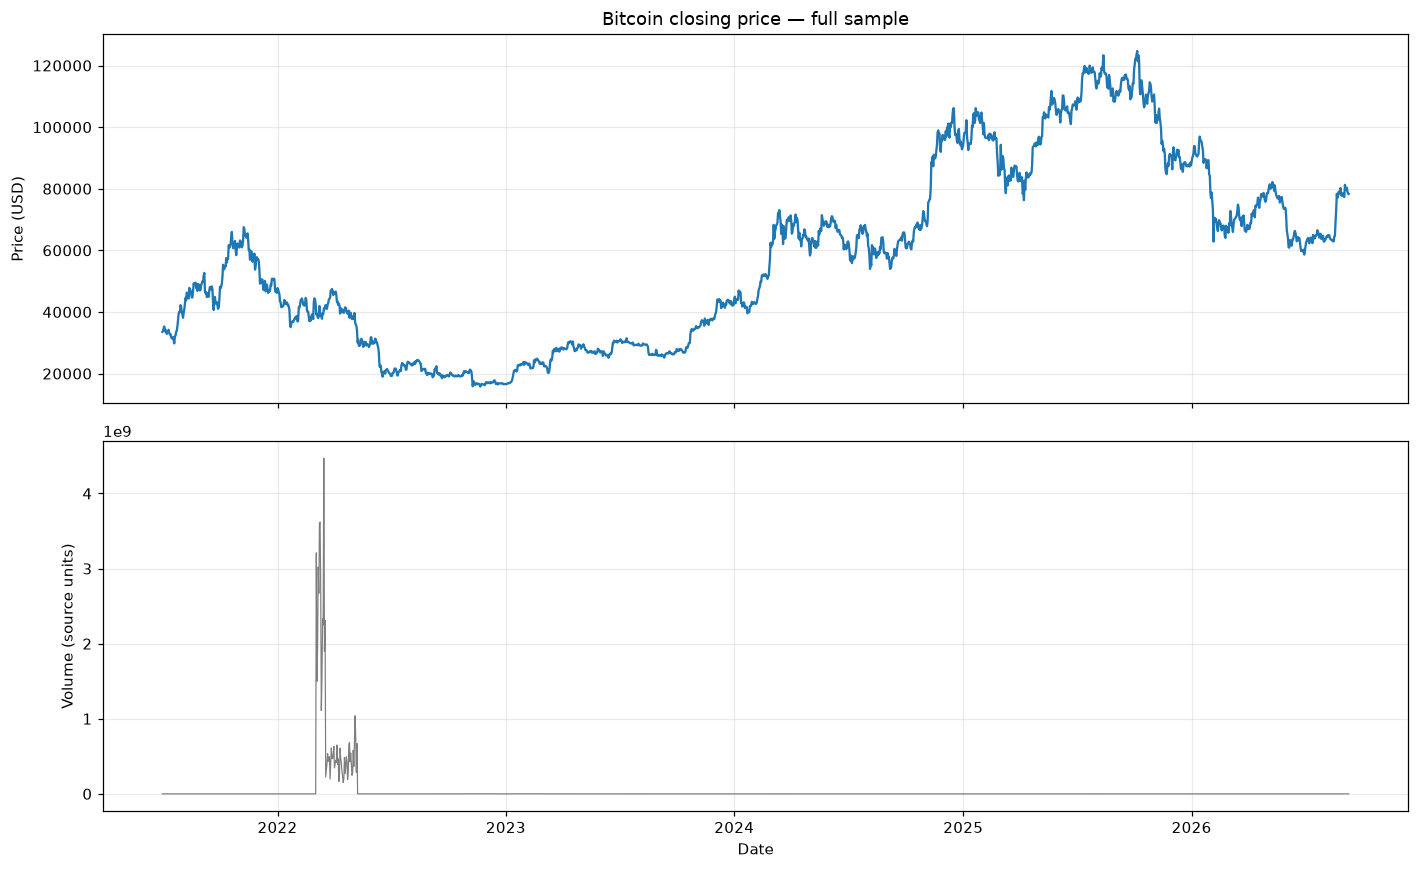

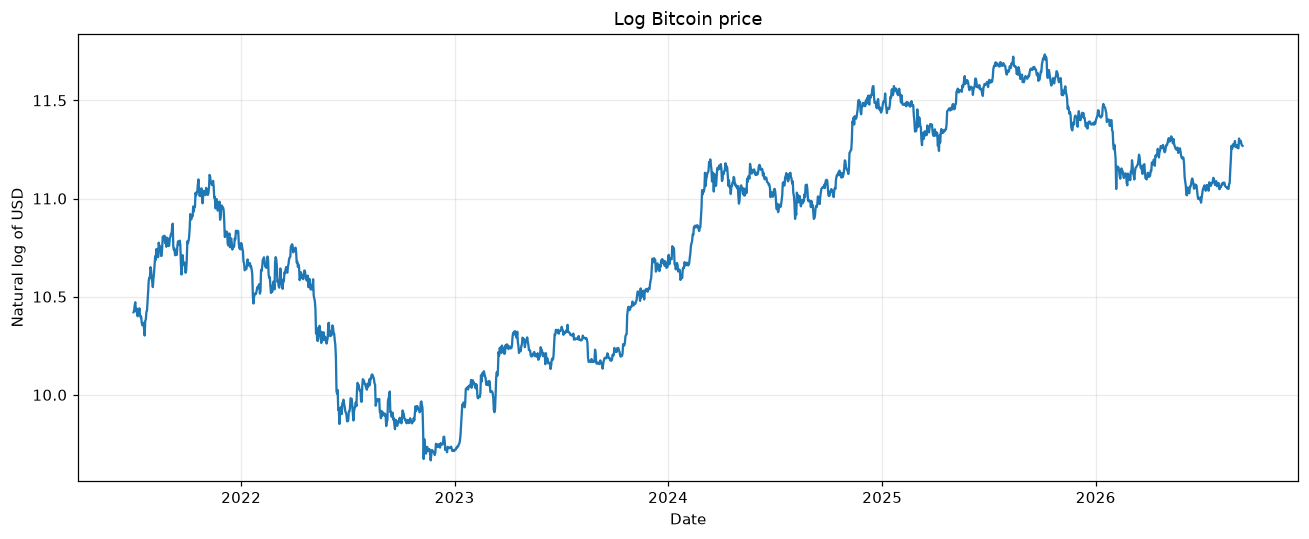

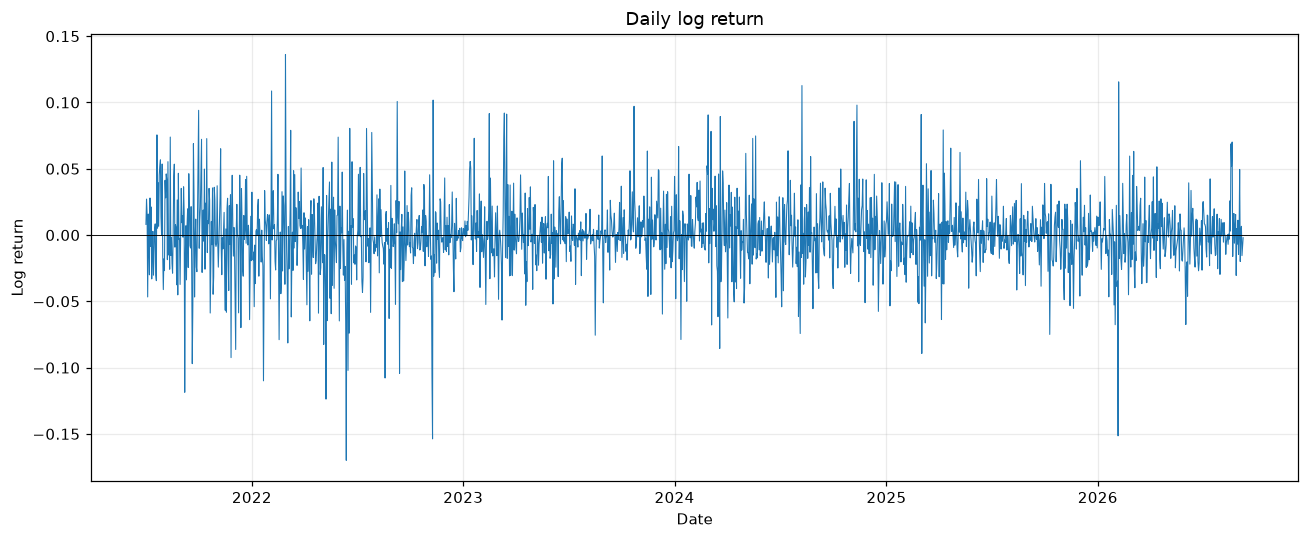

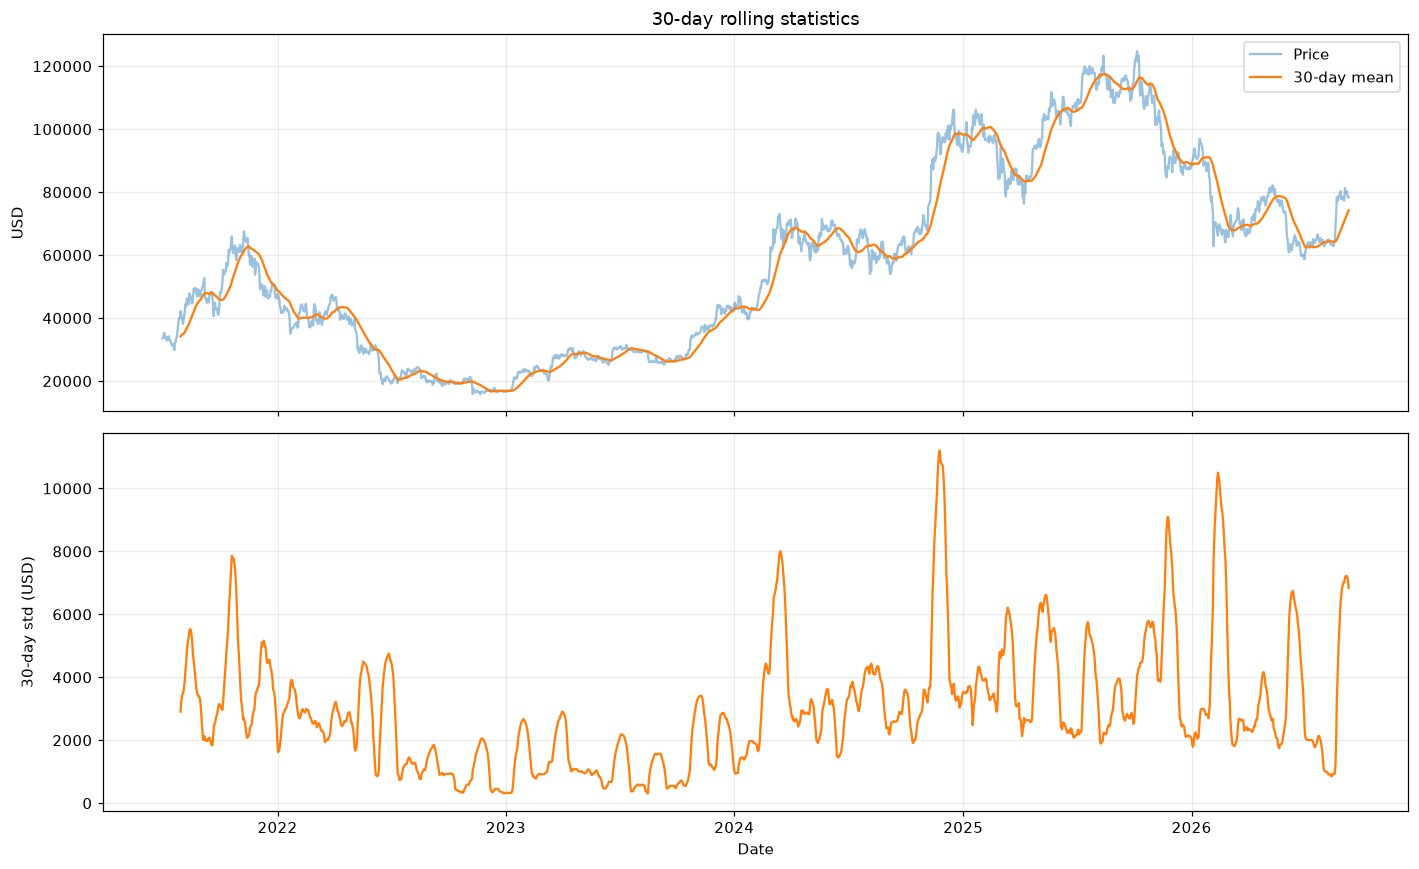

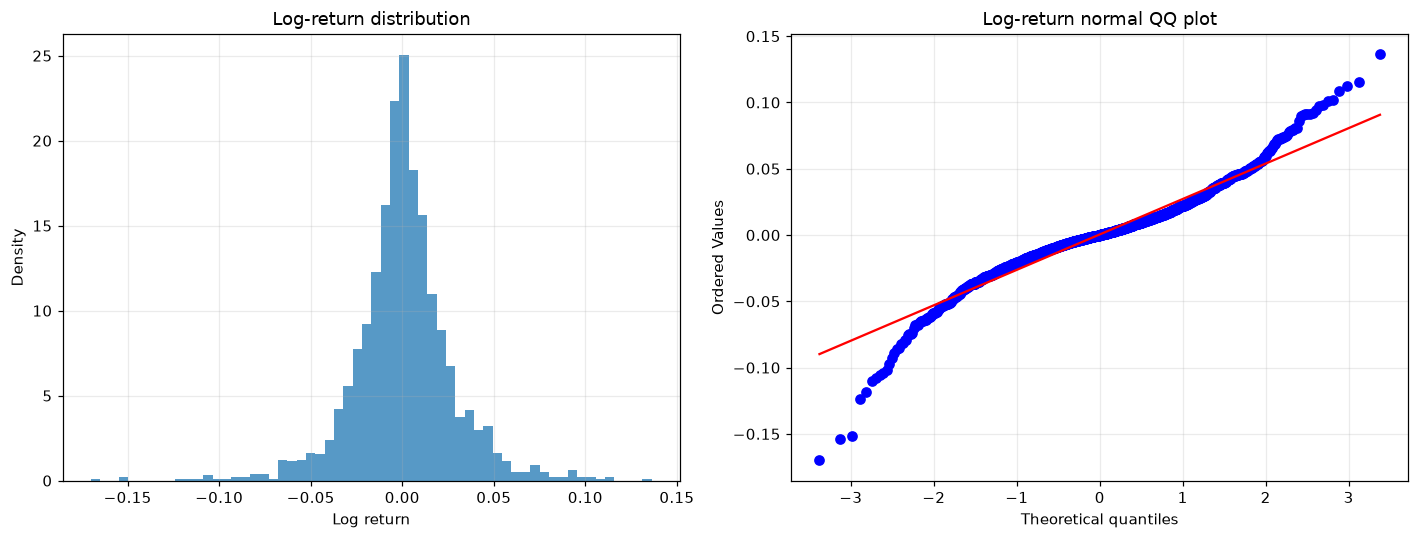

In [3]:
# First figure: raw USD price and volume over the full sample.
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df.index, df['Price'], color='tab:blue')
axes[0].set(title='Bitcoin closing price — full sample', ylabel='Price (USD)')
axes[1].plot(df.index, df['Volume'], color='tab:gray', linewidth=0.8)
axes[1].set(ylabel='Volume (source units)', xlabel='Date')
save_figure(fig, '01_raw_price_volume.png')

fig, ax = plt.subplots()
ax.plot(log_price)
ax.set(title='Log Bitcoin price', ylabel='Natural log of USD', xlabel='Date')
save_figure(fig, '02_log_price.png')

log_return = log_price.diff().dropna()
fig, ax = plt.subplots()
ax.plot(log_return, linewidth=0.7)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(title='Daily log return', ylabel='Log return', xlabel='Date')
save_figure(fig, '03_log_return.png')

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df['Price'], alpha=0.45, label='Price')
axes[0].plot(df['Price'].rolling(30).mean(), label='30-day mean')
axes[0].set(ylabel='USD', title='30-day rolling statistics'); axes[0].legend()
axes[1].plot(df['Price'].rolling(30).std(), color='tab:orange')
axes[1].set(ylabel='30-day std (USD)', xlabel='Date')
save_figure(fig, '04_rolling_stats.png')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(log_return, bins=60, density=True, alpha=0.75)
axes[0].set(title='Log-return distribution', xlabel='Log return', ylabel='Density')
stats.probplot(log_return, dist='norm', plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig, '05_return_distribution.png')


### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [ ]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'USD'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,USD,USD,USD
Start,2021-07-01,2021-07-01,2025-08-26
End,2026-09-09,2025-08-25,2026-09-09
Count,1897,1517,380
Mean,57629.849499,51303.65056,82884.701579
SD,29376.877181,28293.431673,17763.14492
Min,15776.2,15776.2,58630.8
Q1,29798.5,27603.3,67206.375
Median,57534.6,43188.2,78230.25
Q3,78333.9,66798.7,92535.0


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-08-26
End,2026-09-09,2025-08-25,2026-09-09
Count,1896,1516,380
Mean,0.000447,0.000784,-0.000897
SD,0.027453,0.028476,0.022908
Min,-0.169947,-0.169947,-0.151458
Q1,-0.01253,-0.012301,-0.014073
Median,-0.000094,-0.000025,-0.000511
Q3,0.013332,0.014076,0.011167


## Step 3 — Chronological Train/Test Split


,split,start_date,end_date,n_days,min,max,mean
0,Train,2021-07-01,2025-08-25,1517,15776.2,123323.4,51303.650560
1,Test,2025-08-26,2026-09-09,380,58630.8,124725.1,82884.701579


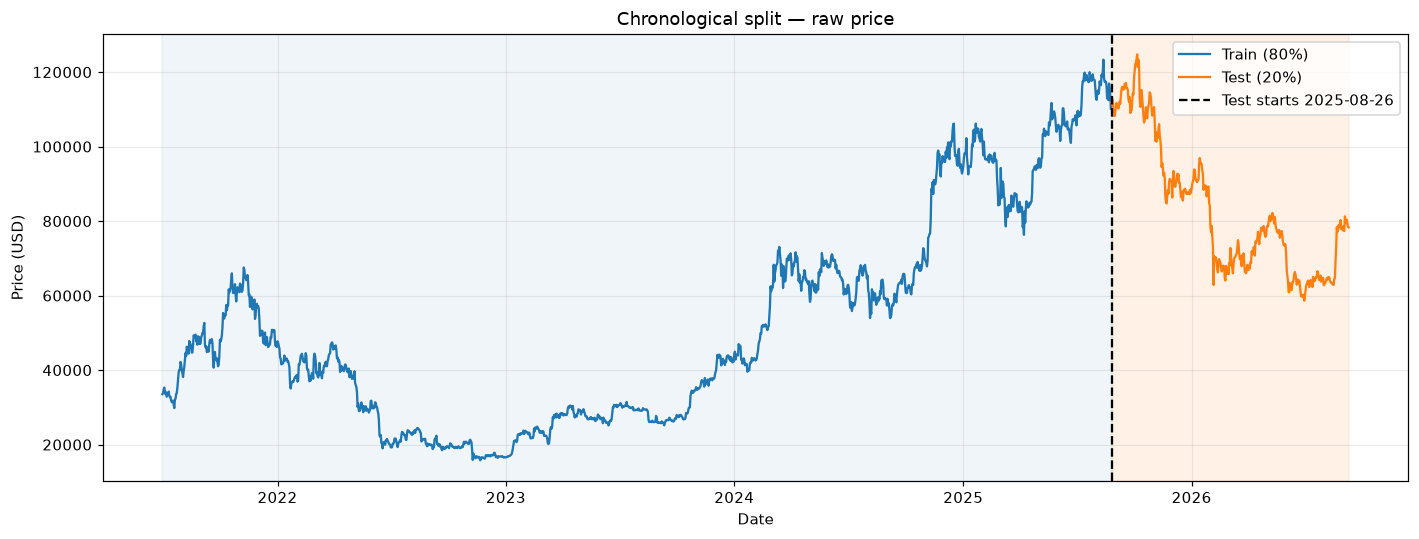

In [4]:
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
train_price = df['Price'].iloc[:n_train].copy()
test_price = df['Price'].iloc[n_train:].copy()
train_log = log_price.iloc[:n_train].copy()
assert (n_train, n_test) == (1517, 380)
assert train_log.index[-1] == pd.Timestamp('2025-08-25')
assert test_price.index[0] == pd.Timestamp('2025-08-26')
split_summary = pd.DataFrame([dict(split=name, start_date=x.index[0].date(),
    end_date=x.index[-1].date(), n_days=len(x), min=x.min(), max=x.max(), mean=x.mean())
    for name, x in [('Train', train_price), ('Test', test_price)]])
save_table(split_summary, 'split_summary.csv')
display(split_summary)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train_price, label='Train (80%)', color='tab:blue')
ax.plot(test_price, label='Test (20%)', color='tab:orange')
ax.axvspan(df.index[0], test_price.index[0], color='tab:blue', alpha=0.07)
ax.axvspan(test_price.index[0], df.index[-1], color='tab:orange', alpha=0.10)
ax.axvline(test_price.index[0], color='black', linestyle='--', label='Test starts 2025-08-26')
ax.set(title='Chronological split — raw price', ylabel='Price (USD)', xlabel='Date')
ax.legend()
save_figure(fig, '06_train_test_split.png')


## Step 4 — Stationarity (Train Only)
ADF: H0 = non-stationary, ผ่านเมื่อ p < 0.05. KPSS: H0 = stationary,
ผ่านเมื่อ p > 0.05. KPSS p-values อาจเป็นขอบเขตจากตารางทดสอบ จึงเก็บ warnings ไว้
หากผลจริงไม่สนับสนุน d=1 โค้ดจะหยุดก่อนเลือกโมเดล ไม่เปลี่ยน d ตามผล test


In [5]:
train_diff = train_log.diff().dropna()
stationarity_rows = []
for series_name, values in [('log_price', train_log), ('diff_log_price', train_diff)]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        adf = adfuller(values, autolag='AIC')
    stationarity_rows.append(dict(series=series_name, test='ADF', statistic=adf[0],
        p_value=adf[1], critical_values=json.dumps(adf[4]),
        conclusion='stationary' if adf[1] < ALPHA else 'non-stationary (fail to reject H0)',
        stationary=adf[1] < ALPHA, warnings=warning_text(caught)))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        kp = kpss(values, regression='c', nlags='auto')
    stationarity_rows.append(dict(series=series_name, test='KPSS', statistic=kp[0],
        p_value=kp[1], critical_values=json.dumps(kp[3]),
        conclusion='stationary (fail to reject H0)' if kp[1] > ALPHA else 'non-stationary',
        stationary=kp[1] > ALPHA, warnings=warning_text(caught)))
stationarity_tests = pd.DataFrame(stationarity_rows)
save_table(stationarity_tests, 'stationarity_tests.csv')
display(stationarity_tests)
level_stationary = stationarity_tests.loc[stationarity_tests['series'].eq('log_price'), 'stationary'].all()
diff_stationary = stationarity_tests.loc[stationarity_tests['series'].eq('diff_log_price'), 'stationary'].all()
assert not level_stationary and diff_stationary, 'Train ADF/KPSS do not jointly support the specified d=1.'
d = 1
print('Train stationarity evidence supports d =', d)


,series,test,statistic,p_value,critical_values,conclusion,stationary,warnings
0,log_price,ADF,-0.377131,0.913848,"{""1%"": -3.434670849024842, ""5%"": -2.8634483841...",non-stationary (fail to reject H0),False,adfuller currently returns a plain tuple whose...
1,log_price,KPSS,3.407253,0.010000,"{""10%"": 0.347, ""5%"": 0.463, ""2.5%"": 0.574, ""1%...",non-stationary,False,The test statistic is outside of the range of ...
2,diff_log_price,ADF,-39.627928,0.000000,"{""1%"": -3.4346737059247014, ""5%"": -2.863449644...",stationary,True,adfuller currently returns a plain tuple whose...
3,diff_log_price,KPSS,0.227228,0.100000,"{""10%"": 0.347, ""5%"": 0.463, ""2.5%"": 0.574, ""1%...",stationary (fail to reject H0),True,The test statistic is outside of the range of ...


Train stationarity evidence supports d = 1


## Step 5 — Model Identification (Train Only)
Grid: p,q=0..5, d=1, trend='n' หรือ 't' (drift).
เก็บ warnings/errors และ convergence ทุกแบบ; เฉพาะโมเดล converged ที่ AIC finite
เข้าสู่ candidate 3 ตัวแรก ไม่มีการ refit candidate ซ้ำเพื่อพยากรณ์

Cross-check เป็นข้อมูลประกอบ ไม่ใช้ผลบน test หรือ auto_arima เปลี่ยนกติกาเลือกโมเดล
ตั้ง `max_order=None` เพื่อไม่ให้ค่า default max_order=5 จำกัดกริด p+q
และใช้ `with_intercept=False/True` แยกสองครั้งเพื่อเทียบ no drift กับ drift
AIC ของ pmdarima อาจต่างจาก statsmodels เพราะการกำหนด trend/likelihood ต่างกัน


**AIC Rank:** 

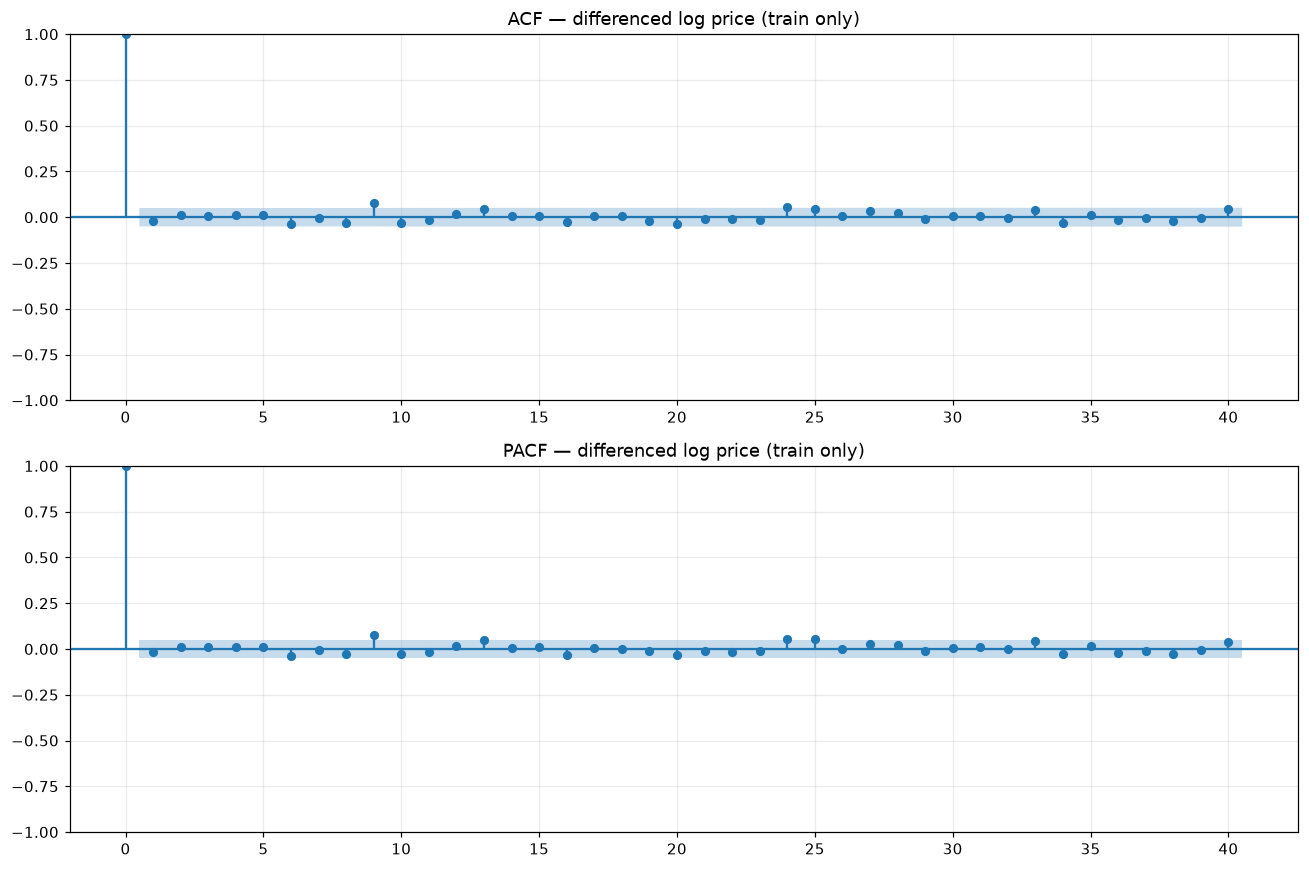

Grid progress: p=0, 12/72 fits completed


Grid progress: p=1, 24/72 fits completed


Grid progress: p=2, 36/72 fits completed


Grid progress: p=3, 48/72 fits completed


Grid progress: p=4, 60/72 fits completed


Grid progress: p=5, 72/72 fits completed


AIC Rank,model,p,d,q,trend,AIC,BIC,converged,warnings,error
1,"ARIMA(0,1,0), trend=n",0,1,0,n,-6485.634548,-6480.310717,True,,
2,"ARIMA(0,1,0), trend=t",0,1,0,t,-6484.784407,-6474.136746,True,,
3,"ARIMA(1,1,0), trend=n",1,1,0,n,-6484.135371,-6473.487710,True,,
4,"ARIMA(0,1,1), trend=n",0,1,1,n,-6484.119849,-6473.472188,True,,
5,"ARIMA(1,1,0), trend=t",1,1,0,t,-6483.329520,-6467.358028,True,,


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(train_diff, lags=40, ax=axes[0])
plot_pacf(train_diff, lags=40, method='ywm', ax=axes[1])
axes[0].set_title('ACF — differenced log price (train only)')
axes[1].set_title('PACF — differenced log price (train only)')
save_figure(fig, '07_acf_pacf.png')

grid_rows, fitted_models = [], {}
for p in range(MAX_P + 1):
    for q in range(MAX_Q + 1):
        for trend in ['n', 't']:
            label = f'ARIMA({p},{d},{q}), trend={trend}'
            row = dict(model=label, p=p, d=d, q=q, trend=trend, AIC=np.nan,
                       BIC=np.nan, converged=False, warnings='', error='')
            caught = []
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter('always')
                    result = ARIMA(train_log, order=(p, d, q), trend=trend).fit()
                row.update(AIC=result.aic, BIC=result.bic,
                           converged=bool(result.mle_retvals.get('converged', False)))
                fitted_models[label] = result
            except Exception as exc:
                row['error'] = f'{type(exc).__name__}: {exc}'
            row['warnings'] = warning_text(caught)
            grid_rows.append(row)
    print(f'Grid progress: p={p}, {len(grid_rows)}/72 fits completed', flush=True)
grid_search = pd.DataFrame(grid_rows).sort_values(['AIC', 'BIC', 'model'], na_position='last').reset_index(drop=True)
# Sequential rank among eligible Train fits; ties use BIC, then model name.
eligible_mask = grid_search['converged'] & np.isfinite(grid_search['AIC']) & grid_search['error'].eq('')
grid_search.insert(0, 'AIC Rank', pd.Series(pd.NA, index=grid_search.index, dtype='Int64'))
grid_search.loc[eligible_mask, 'AIC Rank'] = np.arange(1, int(eligible_mask.sum()) + 1)
save_table(grid_search, 'grid_search_aic_bic.csv')
eligible = grid_search.loc[eligible_mask].copy()
assert len(eligible) >= 3, 'Fewer than three converged grid candidates; inspect grid_search_aic_bic.csv'
candidates = eligible.head(3).copy()
save_table(candidates, 'top3_candidates.csv')
# Display Top 5 for comparison; candidates remains the original Top 3 for selection.
aic_rank_preview = eligible.head(5).copy()
display(aic_rank_preview.style.format({'AIC': '{:.6f}', 'BIC': '{:.6f}'}).hide(axis='index'))


In [7]:
cross_rows = []
for intercept in [False, True]:
    caught = []
    row = dict(with_intercept=intercept, order='', AIC=np.nan, BIC=np.nan,
               converged=False, warnings='', error='')
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            cross = pm.auto_arima(train_log, d=1, seasonal=False, stepwise=False,
                information_criterion='aic', start_p=0, start_q=0,
                max_p=MAX_P, max_q=MAX_Q, max_order=None, with_intercept=intercept,
                suppress_warnings=False, error_action='warn', n_jobs=1)
        row.update(order=str(cross.order), AIC=cross.aic(), BIC=cross.bic(),
                   converged=bool(cross.arima_res_.mle_retvals.get('converged', False)))
    except Exception as exc:
        row['error'] = f'{type(exc).__name__}: {exc}'
    row['warnings'] = warning_text(caught)
    cross_rows.append(row)
    print(f'auto_arima cross-check complete: with_intercept={intercept}', flush=True)
cross_check = pd.DataFrame(cross_rows)
save_table(cross_check, 'auto_arima_cross_check.csv')
display(cross_check)
assert cross_check['error'].eq('').all(), 'auto_arima cross-check failed; inspect saved errors'


auto_arima cross-check complete: with_intercept=False


auto_arima cross-check complete: with_intercept=True


,with_intercept,order,AIC,BIC,converged,warnings,error
0,False,"(0, 1, 0)",-6485.634548,-6480.310717,True,Maximum Likelihood optimization failed to conv...,
1,True,"(0, 1, 0)",-6484.784454,-6474.136793,True,Non-stationary starting autoregressive paramet...,


## Step 6 — Residual Diagnostics & Final Model (Train Only)
ใช้ resid[1:] ตามสเปก ทดสอบ Ljung–Box ที่ 10,20,30 โดย model_df=p+q
เลือก AIC ต่ำสุดใน 3 candidates ที่ผ่านทั้ง Ljung–Box และ roots.
รากที่ไม่มี (p=0 หรือ q=0) ถือว่าเงื่อนไขผ่านโดยไม่มีรากให้ละเมิด และรายงาน N/A
Mean/ARCH/normality/parameter significance ใช้รายงาน ไม่ใช้คัดทิ้ง
หากทั้งสามไม่ผ่าน โค้ดหยุดพร้อมเหตุผล ไม่ใช้ test เลือกโมเดลทดแทน


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,model,AIC,ljung_box_pass,roots_pass,arch_pvalue
0,"ARIMA(0,1,0), trend=n",-6485.634548,True,True,0.000002
1,"ARIMA(0,1,0), trend=t",-6484.784407,True,True,0.000001
2,"ARIMA(1,1,0), trend=n",-6484.135371,True,True,0.000002


,model,test,statistic,p_value,pass_fail,note
0,"ARIMA(0,1,0), trend=n",Ljung-Box lag 10,15.794019,1.056826e-01,PASS,model_df=0
1,"ARIMA(0,1,0), trend=n",Ljung-Box lag 20,24.111896,2.375385e-01,PASS,model_df=0
2,"ARIMA(0,1,0), trend=n",Ljung-Box lag 30,35.331448,2.307803e-01,PASS,model_df=0
3,"ARIMA(0,1,0), trend=n",Mean = 0 (t-test),1.072146,2.838251e-01,PASS,Residual mean=0.00078411
4,"ARIMA(0,1,0), trend=n",ARCH LM (10 lags),45.710331,1.618327e-06,FAIL,
5,"ARIMA(0,1,0), trend=n",Jarque-Bera,830.704210,4.119767e-181,FAIL,"skew=-0.1801, kurtosis=6.6085"
6,"ARIMA(0,1,0), trend=n",AR roots outside unit circle,NaN,NaN,PASS,N/A: no roots
7,"ARIMA(0,1,0), trend=n",MA roots outside unit circle,NaN,NaN,PASS,N/A: no roots
8,"ARIMA(0,1,0), trend=n",Parameter significance: sigma2,0.000811,0.000000e+00,PASS,"Report only; estimate in statistic column, sig..."
9,"ARIMA(0,1,0), trend=t",Ljung-Box lag 10,15.794019,1.056826e-01,PASS,model_df=0


Selected: ARIMA(0,1,0), trend=n


,model,parameter,estimate,standard_error,p_value,significant,covariance
0,"ARIMA(0,1,0), trend=n",sigma2,0.000811,0.000018,0.0,True,opg


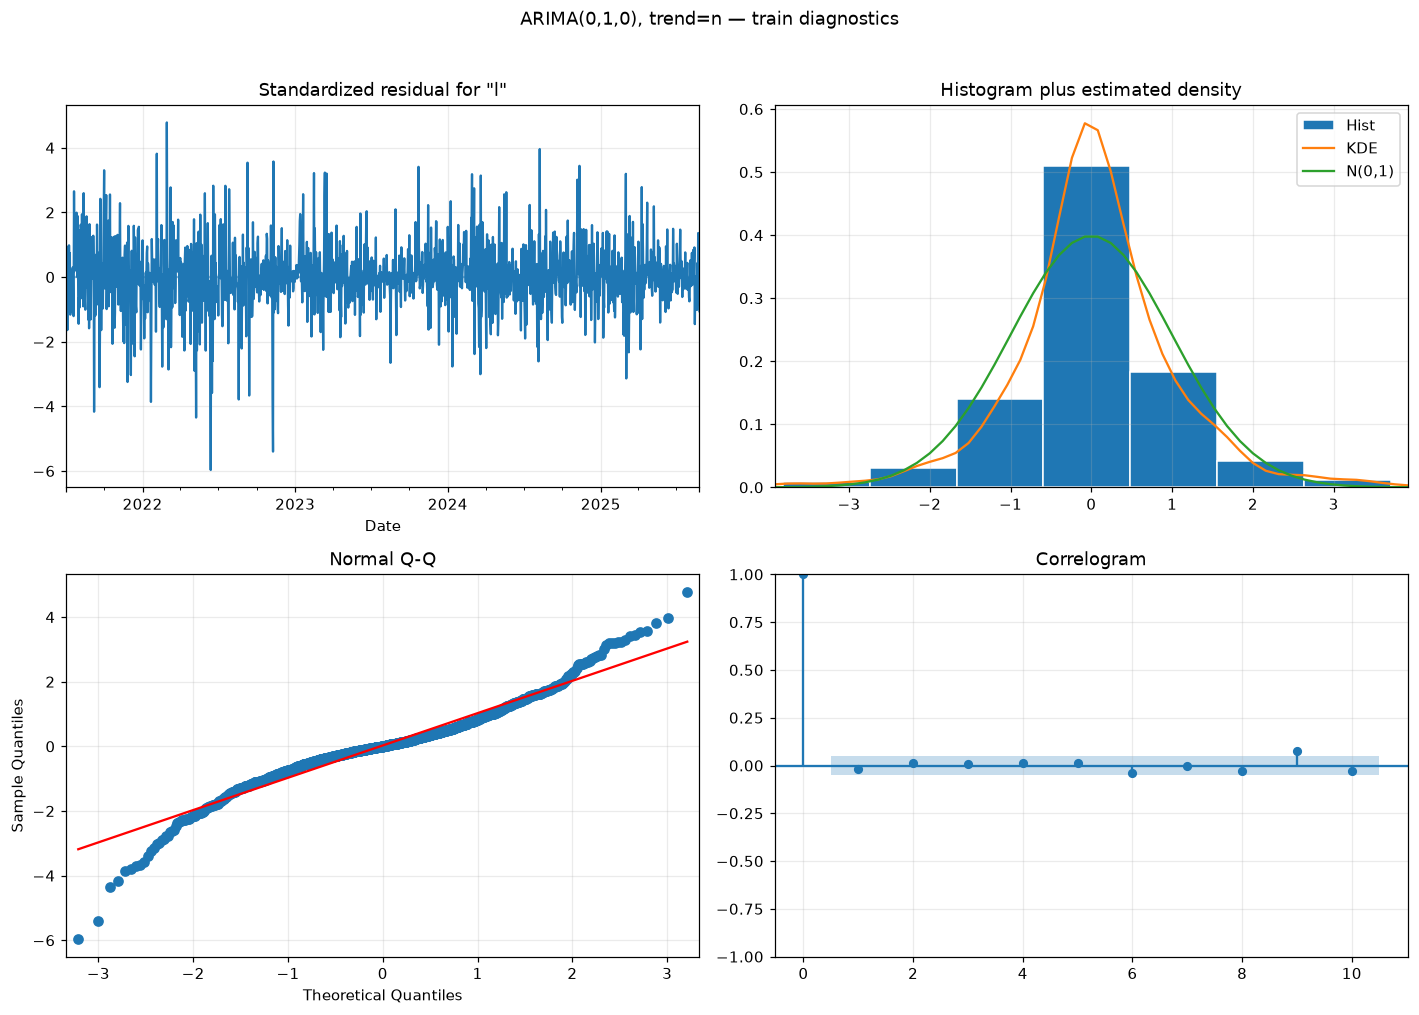

,model,parameter,estimate,robust_standard_error,robust_p_value,converged,warnings
0,"ARIMA(0,1,0), trend=n",sigma2,0.000811,0.000049,5.776823e-61,True,


                               SARIMAX Results                                
Dep. Variable:              log_price   No. Observations:                 1517
Model:                 ARIMA(0, 1, 0)   Log Likelihood                3243.817
Date:                Sat, 10 Oct 2026   AIC                          -6485.635
Time:                        18:33:46   BIC                          -6480.311
Sample:                    07-01-2021   HQIC                         -6483.652
                         - 08-25-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0008   1.76e-05     46.016      0.000       0.001       0.001
Ljung-Box (L1) (Q):                   0.55   Jarque-Bera (JB):               830.70
Prob(Q):                              0.46   Pr

In [8]:
check_rows, parameter_rows, root_rows, candidate_status = [], [], [], []
robust_results, robust_rows, robust_warning_messages = {}, [], {}
def add_check(model, test, statistic=np.nan, p_value=np.nan, passed=None, note=''):
    check_rows.append(dict(model=model, test=test, statistic=statistic, p_value=p_value,
                           pass_fail='PASS' if passed else 'FAIL', note=note))

for item in candidates.itertuples(index=False):
    result = fitted_models[item.model]
    residuals = pd.Series(np.asarray(result.resid)[1:]).dropna()
    lb = acorr_ljungbox(residuals, lags=[10, 20, 30], model_df=item.p + item.q, return_df=True)
    lb_pass = bool(lb['lb_pvalue'].notna().all() and (lb['lb_pvalue'] > ALPHA).all())
    for lag, row in lb.iterrows():
        add_check(item.model, f'Ljung-Box lag {lag}', row['lb_stat'], row['lb_pvalue'],
                  bool(row['lb_pvalue'] > ALPHA), f'model_df={item.p + item.q}')
    mean_stat, mean_p = stats.ttest_1samp(residuals, 0)
    add_check(item.model, 'Mean = 0 (t-test)', mean_stat, mean_p, mean_p > ALPHA,
              f'Residual mean={residuals.mean():.6g}')
    arch_stat, arch_p, _, _ = het_arch(residuals, nlags=10)
    add_check(item.model, 'ARCH LM (10 lags)', arch_stat, arch_p, arch_p > ALPHA)
    if arch_p <= ALPHA:
        with warnings.catch_warnings(record=True) as robust_caught:
            warnings.simplefilter('always')
            robust = ARIMA(train_log, order=(item.p, d, item.q), trend=item.trend).fit(cov_type='robust')
        robust_results[item.model] = robust
        robust_warning_messages[item.model] = warning_text(robust_caught)
        for name, coef, se, pv in zip(robust.param_names, robust.params, robust.bse, robust.pvalues):
            robust_rows.append(dict(model=item.model, parameter=name, estimate=coef,
                robust_standard_error=se, robust_p_value=pv,
                converged=bool(robust.mle_retvals.get('converged', False)),
                warnings=warning_text(robust_caught)))
    jb_stat, jb_p, skew, kurt = jarque_bera(residuals)
    add_check(item.model, 'Jarque-Bera', jb_stat, jb_p, jb_p > ALPHA,
              f'skew={skew:.4f}, kurtosis={kurt:.4f}')
    roots_pass = True
    for kind, roots in [('AR', result.arroots), ('MA', result.maroots)]:
        moduli = np.abs(roots)
        passed = bool((moduli > 1).all())
        roots_pass &= passed
        add_check(item.model, f'{kind} roots outside unit circle',
                  moduli.min() if len(moduli) else np.nan, passed=passed,
                  note='N/A: no roots' if not len(moduli) else f'All |root|>1: {passed}')
        for j, root in enumerate(roots, 1):
            root_rows.append(dict(model=item.model, kind=kind, root_number=j,
                                  real=root.real, imag=root.imag, modulus=abs(root), outside=abs(root) > 1))
    for name, coef, se, pv in zip(result.param_names, result.params, result.bse, result.pvalues):
        parameter_rows.append(dict(model=item.model, parameter=name, estimate=coef, standard_error=se,
                                   p_value=pv, significant=pv < ALPHA, covariance=result.cov_type))
        add_check(item.model, f'Parameter significance: {name}', coef, pv, pv < ALPHA,
                  'Report only; estimate in statistic column, significance uses p < alpha')
    candidate_status.append(dict(model=item.model, AIC=item.AIC, ljung_box_pass=lb_pass,
                                 roots_pass=roots_pass, arch_pvalue=arch_p))

assumption_checks = pd.DataFrame(check_rows)
parameter_significance = pd.DataFrame(parameter_rows)
candidate_diagnostics = pd.DataFrame(candidate_status).sort_values('AIC')
save_table(assumption_checks, 'assumption_checks.csv')
save_table(parameter_significance, 'parameter_significance.csv')
save_table(pd.DataFrame(root_rows, columns=['model','kind','root_number','real','imag','modulus','outside']), 'model_roots.csv')
save_table(candidate_diagnostics, 'candidate_diagnostics.csv')
if robust_rows:
    save_table(pd.DataFrame(robust_rows), 'robust_parameter_significance.csv')
display(candidate_diagnostics)
display(assumption_checks)
passing = candidate_diagnostics.loc[candidate_diagnostics['ljung_box_pass'] & candidate_diagnostics['roots_pass']]
assert not passing.empty, 'No top-3 candidate passes Ljung-Box and roots. Review train-only diagnostics; do not relax using test.'
final_label = passing.iloc[0]['model']
final_spec = candidates.set_index('model').loc[final_label]
res = fitted_models[final_label]  # reuse original train fit; frozen forecast parameters
frozen_params = np.asarray(res.params).copy()
assert res.nobs == n_train
print('Selected:', final_label)
display(parameter_significance.loc[parameter_significance['model'].eq(final_label)])
fig = res.plot_diagnostics(figsize=(13, 9))
fig.suptitle(f'{final_label} — train diagnostics', y=1.02)
save_figure(fig, '08_residual_diagnostics.png')

summary_text = res.summary().as_text()
robust_res = None
if passing.iloc[0]['arch_pvalue'] <= ALPHA:
    robust_res = robust_results[final_label]
    display(pd.DataFrame(robust_rows).loc[lambda x: x['model'].eq(final_label)])
    summary_text += '\n\nROBUST COVARIANCE REFIT ON TRAIN — reporting only; forecasts retain original parameters.\n'
    summary_text += robust_res.summary().as_text()
    summary_text += '\nWarnings: ' + robust_warning_messages[final_label]
    summary_text += '\nRobust refit converged: ' + str(robust_res.mle_retvals.get('converged', False))
assert np.array_equal(np.asarray(res.params), frozen_params)
(SUMMARY_DIR / 'final_model_summary.txt').write_text(summary_text, encoding='utf-8')
print(summary_text)


## Step 7 - Forecast Values by Horizon
The next cells produce forecasts using the parameters estimated on train.
`arima_fc` is the point forecast in USD; `arima_lo95` and `arima_hi95` are its model-based 95% prediction-interval bounds.
The exp-transformed log forecast mean is a conditional median on the USD scale.

### 7.1 Rolling-origin forecasts for the test period
Each origin uses observations up to that date only, with `refit=False`.

In [9]:
log_all = log_price
forecast_rows = []
for i in range(n_train - 1, n - 1):
    r = res.apply(log_all.iloc[:i+1], refit=False)
    assert np.array_equal(np.asarray(r.params), frozen_params), 'Parameters changed during test'
    fc = r.get_forecast(steps=max(HORIZONS))
    means = np.asarray(fc.predicted_mean)
    ci = np.asarray(fc.conf_int(alpha=ALPHA))
    for h in HORIZONS:
        target = i + h
        if target < n:
            row = dict(origin_date=log_all.index[i], h=h, target_date=log_all.index[target],
                actual=df['Price'].iloc[target], arima_fc=np.exp(means[h-1]),
                arima_lo95=np.exp(ci[h-1, 0]), arima_hi95=np.exp(ci[h-1, 1]),
                price_origin=df['Price'].iloc[i])
            # Treat rounding noise as zero price movement, not a predicted direction.
            if np.isclose(row['arima_fc'], row['price_origin'], rtol=32*np.finfo(float).eps, atol=0):
                row['arima_fc'] = row['price_origin']
            forecast_rows.append(row)
    if (i - n_train + 2) % 50 == 0:
        print(f'Rolling origins completed: {i - n_train + 2}/{n_test}', flush=True)
forecasts = pd.DataFrame(forecast_rows).sort_values(['h', 'target_date']).reset_index(drop=True)
counts = forecasts.groupby('h').size()
for h in HORIZONS:
    assert counts[h] == n_test - h + 1, (h, counts[h])
assert (forecasts['target_date'] >= test_price.index[0]).all()
assert ((forecasts['target_date'] - forecasts['origin_date']).dt.days == forecasts['h']).all()
assert not forecasts.duplicated(['origin_date', 'h']).any()
assert np.isfinite(forecasts.select_dtypes('number').to_numpy()).all()
assert (forecasts['arima_lo95'] <= forecasts['arima_hi95']).all()
save_table(forecasts, 'forecasts_long.csv')
display(counts.rename('n_points').to_frame())


Rolling origins completed: 50/380


Rolling origins completed: 100/380


Rolling origins completed: 150/380


Rolling origins completed: 200/380


Rolling origins completed: 250/380


Rolling origins completed: 300/380


Rolling origins completed: 350/380


,n_points
h,
1,380
3,378
5,376
7,374
14,367
21,360
30,351


### 7.2 Test forecast tables - h = 1, 3, 5, 7, 14, 21, 30
Each table displays every forecast at that horizon: origin date, target date, price at origin, actual target price, and forecast in USD.
Scroll inside a table to inspect all dates. Full tables are also exported to `OUTPUT/ARIMA_BTC/tables/forecasts_h{h}.csv`.

In [10]:
# All test forecasts are visible in scrollable tables; export all rows per horizon.
forecast_columns = ['origin_date', 'target_date', 'price_origin', 'actual',
                    'arima_fc', 'arima_lo95', 'arima_hi95']
for h in HORIZONS:
    horizon_forecasts = forecasts.loc[forecasts['h'].eq(h), forecast_columns].copy()
    save_table(horizon_forecasts, f'forecasts_h{h}.csv')
    display(Markdown(f'**Test forecasts: h = {h} calendar days ({len(horizon_forecasts)} rows)**'))
    table_html = horizon_forecasts.to_html(index=False, float_format=lambda x: f'{x:,.2f}')
    display(HTML('<div style="max-height:360px;overflow:auto;border:1px solid #ddd;padding:8px">'
                 + table_html + '</div>'))


**Test forecasts: h = 1 calendar days (380 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95
2025-08-25,2025-08-26,"110,118.40","111,768.60","110,118.40","104,141.62","116,438.19"
2025-08-26,2025-08-27,"111,768.60","111,255.60","111,768.60","105,702.26","118,183.10"
2025-08-27,2025-08-28,"111,255.60","112,568.90","111,255.60","105,217.10","117,640.65"
2025-08-28,2025-08-29,"112,568.90","108,355.60","112,568.90","106,459.12","119,029.33"
2025-08-29,2025-08-30,"108,355.60","108,818.10","108,355.60","102,474.50","114,574.22"
2025-08-30,2025-08-31,"108,818.10","108,226.80","108,818.10","102,911.90","115,063.26"
2025-08-31,2025-09-01,"108,226.80","109,243.30","108,226.80","102,352.69","114,438.03"
2025-09-01,2025-09-02,"109,243.30","111,218.30","109,243.30","103,314.02","115,512.87"
2025-09-02,2025-09-03,"111,218.30","111,716.50","111,218.30","105,181.82","117,601.21"
2025-09-03,2025-09-04,"111,716.50","110,712.70","111,716.50","105,652.98","118,128.01"


**Test forecasts: h = 3 calendar days (378 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95
2025-08-25,2025-08-28,"110,118.40","112,568.90","110,118.40","99,972.99","121,293.38"
2025-08-26,2025-08-29,"111,768.60","108,355.60","111,768.60","101,471.15","123,111.05"
2025-08-27,2025-08-30,"111,255.60","108,818.10","111,255.60","101,005.42","122,545.99"
2025-08-28,2025-08-31,"112,568.90","108,226.80","112,568.90","102,197.72","123,992.56"
2025-08-29,2025-09-01,"108,355.60","109,243.30","108,355.60","98,372.60","119,351.69"
2025-08-30,2025-09-02,"108,818.10","111,218.30","108,818.10","98,792.49","119,861.12"
2025-08-31,2025-09-03,"108,226.80","111,716.50","108,226.80","98,255.67","119,209.82"
2025-09-01,2025-09-04,"109,243.30","110,712.70","109,243.30","99,178.51","120,329.47"
2025-09-02,2025-09-05,"111,218.30","110,652.20","111,218.30","100,971.55","122,504.90"
2025-09-03,2025-09-06,"111,716.50","110,194.40","111,716.50","101,423.85","123,053.66"


**Test forecasts: h = 5 calendar days (376 rows)**

...

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95
2025-08-25,2025-09-08,"110,118.40","112,068.40","110,118.40","89,367.32","135,687.87"
2025-08-26,2025-09-09,"111,768.60","111,516.50","111,768.60","90,706.55","137,721.25"
2025-08-27,2025-09-10,"111,255.60","113,963.50","111,255.60","90,290.23","137,089.13"
2025-08-28,2025-09-11,"112,568.90","115,490.20","112,568.90","91,356.04","138,707.38"
2025-08-29,2025-09-12,"108,355.60","116,042.80","108,355.60","87,936.71","133,515.75"
2025-08-30,2025-09-13,"108,818.10","115,924.90","108,818.10","88,312.06","134,085.64"
2025-08-31,2025-09-14,"108,226.80","115,314.60","108,226.80","87,832.18","133,357.04"
2025-09-01,2025-09-15,"109,243.30","115,362.10","109,243.30","88,657.13","134,609.57"
2025-09-02,2025-09-16,"111,218.30","116,795.90","111,218.30","90,259.95","137,043.17"
2025-09-03,2025-09-17,"111,716.50","116,425.90","111,716.50","90,664.27","137,657.05"


**Test forecasts: h = 21 calendar days (360 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95
2025-08-25,2025-09-15,"110,118.40","115,362.10","110,118.40","85,270.46","142,207.06"
2025-08-26,2025-09-16,"111,768.60","116,795.90","111,768.60","86,548.30","144,338.13"
2025-08-27,2025-09-17,"111,255.60","116,425.90","111,255.60","86,151.06","143,675.64"
2025-08-28,2025-09-18,"112,568.90","117,086.00","112,568.90","87,168.02","145,371.64"
2025-08-29,2025-09-19,"108,355.60","115,649.00","108,355.60","83,905.44","139,930.58"
2025-08-30,2025-09-20,"108,818.10","115,699.20","108,818.10","84,263.57","140,527.85"
2025-08-31,2025-09-21,"108,226.80","115,243.00","108,226.80","83,805.70","139,764.24"
2025-09-01,2025-09-22,"109,243.30","112,673.00","109,243.30","84,592.83","141,076.95"
2025-09-02,2025-09-23,"111,218.30","112,002.60","111,218.30","86,122.18","143,627.47"
2025-09-03,2025-09-24,"111,716.50","113,307.10","111,716.50","86,507.96","144,270.85"


**Test forecasts: h = 30 calendar days (351 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95
2025-08-25,2025-09-24,"110,118.40","113,307.10","110,118.40","81,117.82","149,487.02"
2025-08-26,2025-09-25,"111,768.60","109,016.30","111,768.60","82,333.43","151,727.19"
2025-08-27,2025-09-26,"111,255.60","109,662.20","111,255.60","81,955.53","151,030.78"
2025-08-28,2025-09-27,"112,568.90","109,652.80","112,568.90","82,922.97","152,813.61"
2025-08-29,2025-09-28,"108,355.60","112,174.60","108,355.60","79,819.27","147,094.00"
2025-08-30,2025-09-29,"108,818.10","114,357.50","108,818.10","80,159.97","147,721.85"
2025-08-31,2025-09-30,"108,226.80","114,048.50","108,226.80","79,724.39","146,919.15"
2025-09-01,2025-10-01,"109,243.30","118,576.20","109,243.30","80,473.19","148,299.06"
2025-09-02,2025-10-02,"111,218.30","120,566.10","111,218.30","81,928.06","150,980.15"
2025-09-03,2025-10-03,"111,716.50","122,224.20","111,716.50","82,295.05","151,656.46"


### 7.3 Future forecasts from the latest observed date
This seven-row table uses a common origin: the final date in the CSV. Target dates are 1, 3, 5, 7, 14, 21 and 30 calendar days later.
Only filtering states are updated with the full observed history; model order and train-estimated parameters remain fixed.
These are future values, separate from the historical test forecasts evaluated below. No future actual prices are assumed.

In [11]:
# Update filtering states with the latest observed data, keeping train parameters fixed.
latest_origin = log_all.index[-1]
latest_result = res.apply(log_all, refit=False)
assert np.array_equal(np.asarray(latest_result.params), frozen_params)
latest_fc = latest_result.get_forecast(steps=max(max(HORIZONS), max(DAILY_FORECAST_WINDOWS)))
latest_means = np.exp(np.asarray(latest_fc.predicted_mean))
latest_ci = np.exp(np.asarray(latest_fc.conf_int(alpha=ALPHA)))
latest_price = float(df['Price'].iloc[-1])
future_rows = []
for h in HORIZONS:
    value = latest_means[h-1]
    if np.isclose(value, latest_price, rtol=32*np.finfo(float).eps, atol=0):
        value = latest_price
    future_rows.append(dict(origin_date=latest_origin, h=h,
        target_date=latest_origin + pd.Timedelta(days=h),
        arima_fc=value, arima_lo95=latest_ci[h-1, 0], arima_hi95=latest_ci[h-1, 1]))
future_forecasts = pd.DataFrame(future_rows)
assert future_forecasts['h'].tolist() == HORIZONS
assert (future_forecasts['target_date'] > df.index[-1]).all()
save_table(future_forecasts, 'future_forecast_by_horizon.csv')
print(f'Forecast origin: {latest_origin.date()}, last observed price: {latest_price:,.2f} USD')
display(future_forecasts.style.format({'origin_date': lambda x: x.strftime('%Y-%m-%d'),
    'target_date': lambda x: x.strftime('%Y-%m-%d'),
    'arima_fc': '{:,.2f}', 'arima_lo95': '{:,.2f}', 'arima_hi95': '{:,.2f}'}).hide(axis='index'))


C:\Users\User\AppData\Local\Temp\ipykernel_39008\1581401926.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  target_date=latest_origin + pd.Timedelta(days=h),


Forecast origin: 2026-09-09, last observed price: 78,297.00 USD


origin_date,h,target_date,arima_fc,arima_lo95,arima_hi95
2026-09-09,1,2026-09-10,"78,297.00","74,047.36","82,790.53"
2026-09-09,3,2026-09-12,"78,297.00","71,083.35","86,242.70"
2026-09-09,5,2026-09-14,"78,297.00","69,111.89","88,702.83"
2026-09-09,7,2026-09-16,"78,297.00","67,549.77","90,754.12"
2026-09-09,14,2026-09-23,"78,297.00","63,542.45","96,477.55"
2026-09-09,21,2026-09-30,"78,297.00","60,629.48","101,112.86"
2026-09-09,30,2026-10-09,"78,297.00","57,676.85","106,289.10"


### 7.4 Daily future forecast tables  next 7 and 30 calendar days
 `OUTPUT/ARIMA_BTC/tables/future_forecast_daily_7d.csv`  `future_forecast_daily_30d.csv`.


In [12]:
# Reuse the same latest-origin forecast path; no model fitting or selection.
daily_steps = max(DAILY_FORECAST_WINDOWS)
daily_dates = pd.date_range(latest_origin + pd.Timedelta(days=1), periods=daily_steps, freq='D')
daily_point = latest_means[:daily_steps].copy()
daily_point[np.isclose(daily_point, latest_price, rtol=32*np.finfo(float).eps, atol=0)] = latest_price
future_forecast_daily = pd.DataFrame({
    'origin_date': latest_origin,
    'h': np.arange(1, daily_steps + 1),
    'target_date': daily_dates,
    'day_of_week': daily_dates.day_name(),
    'price_origin': latest_price,
    'arima_fc': daily_point,
    'arima_lo95': latest_ci[:daily_steps, 0],
    'arima_hi95': latest_ci[:daily_steps, 1],
})
assert np.array_equal(np.asarray(latest_result.params), frozen_params)
assert len(future_forecast_daily) == daily_steps
assert ((future_forecast_daily['target_date'] - latest_origin).dt.days == future_forecast_daily['h']).all()
assert not future_forecast_daily['target_date'].duplicated().any()
assert np.isfinite(future_forecast_daily.select_dtypes('number').to_numpy()).all()
assert (future_forecast_daily[['price_origin', 'arima_fc', 'arima_lo95', 'arima_hi95']] > 0).all().all()
assert (future_forecast_daily['arima_lo95'] <= future_forecast_daily['arima_fc']).all()
assert (future_forecast_daily['arima_fc'] <= future_forecast_daily['arima_hi95']).all()
# Requested-horizon rows must agree with section 7.3.
np.testing.assert_allclose(
    future_forecast_daily.set_index('h').loc[HORIZONS, ['arima_fc', 'arima_lo95', 'arima_hi95']],
    future_forecasts.set_index('h').loc[HORIZONS, ['arima_fc', 'arima_lo95', 'arima_hi95']],
    rtol=1e-12,
)
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} calendar days ? origin {latest_origin.date()}, last price {latest_price:,.2f} USD**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.2f}')))


C:\Users\User\AppData\Local\Temp\ipykernel_39008\1490812489.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  daily_dates = pd.date_range(latest_origin + pd.Timedelta(days=1), periods=daily_steps, freq='D')


**Next 7 calendar days ? origin 2026-09-09, last price 78,297.00 USD**

origin_date,h,target_date,day_of_week,price_origin,arima_fc,arima_lo95,arima_hi95
2026-09-09,1,2026-09-10,Thursday,"78,297.00","78,297.00","74,047.36","82,790.53"
2026-09-09,2,2026-09-11,Friday,"78,297.00","78,297.00","72,355.39","84,726.52"
2026-09-09,3,2026-09-12,Saturday,"78,297.00","78,297.00","71,083.35","86,242.70"
2026-09-09,4,2026-09-13,Sunday,"78,297.00","78,297.00","70,028.37","87,541.95"
2026-09-09,5,2026-09-14,Monday,"78,297.00","78,297.00","69,111.89","88,702.83"
2026-09-09,6,2026-09-15,Tuesday,"78,297.00","78,297.00","68,293.66","89,765.58"
2026-09-09,7,2026-09-16,Wednesday,"78,297.00","78,297.00","67,549.77","90,754.12"


**Next 30 calendar days ? origin 2026-09-09, last price 78,297.00 USD**

origin_date,h,target_date,day_of_week,price_origin,arima_fc,arima_lo95,arima_hi95
2026-09-09,1,2026-09-10,Thursday,"78,297.00","78,297.00","74,047.36","82,790.53"
2026-09-09,2,2026-09-11,Friday,"78,297.00","78,297.00","72,355.39","84,726.52"
2026-09-09,3,2026-09-12,Saturday,"78,297.00","78,297.00","71,083.35","86,242.70"
2026-09-09,4,2026-09-13,Sunday,"78,297.00","78,297.00","70,028.37","87,541.95"
2026-09-09,5,2026-09-14,Monday,"78,297.00","78,297.00","69,111.89","88,702.83"
2026-09-09,6,2026-09-15,Tuesday,"78,297.00","78,297.00","68,293.66","89,765.58"
2026-09-09,7,2026-09-16,Wednesday,"78,297.00","78,297.00","67,549.77","90,754.12"
2026-09-09,8,2026-09-17,Thursday,"78,297.00","78,297.00","66,864.66","91,684.01"
2026-09-09,9,2026-09-18,Friday,"78,297.00","78,297.00","66,227.51","92,566.06"
2026-09-09,10,2026-09-19,Saturday,"78,297.00","78,297.00","65,630.48","93,408.13"


## Step 8 - RMSE and MAPE on Test
**RMSE (USD)** = sqrt(mean((actual - forecast)^2)). **MAPE (%)** = 100 * mean(abs((actual - forecast) / actual)).
Both are computed separately for each horizon using only target dates in test. Lower values indicate smaller errors.
The actual price is needed to calculate errors. Future forecasts in Section 7.3 are not included.

### 8.1 Metrics by horizon

In [13]:
evaluation_rows = []
for h, group in forecasts.groupby('h', sort=True):
    actual = group['actual'].to_numpy()
    predicted = group['arima_fc'].to_numpy()
    error = actual - predicted
    evaluation_rows.append(dict(h=h, n_points=len(group),
        RMSE=np.sqrt(np.mean(error**2)), MAPE=100*np.mean(np.abs(error / actual))))
evaluation = pd.DataFrame(evaluation_rows).sort_values('h').reset_index(drop=True)
assert len(evaluation) == len(HORIZONS)
save_table(evaluation, 'evaluation_by_horizon.csv')
display(evaluation.style.format({'RMSE': '{:,.2f}', 'MAPE': '{:.2f}'}).hide(axis='index'))


h,n_points,RMSE,MAPE
1,380,"1,853.21",1.61
3,378,"3,278.08",2.97
5,376,"4,242.30",3.72
7,374,"5,126.53",4.57
14,367,"7,410.70",6.85
21,360,"9,273.21",8.83
30,351,"11,342.72",11.13


### 8.2 Actual and forecast plots for each horizon

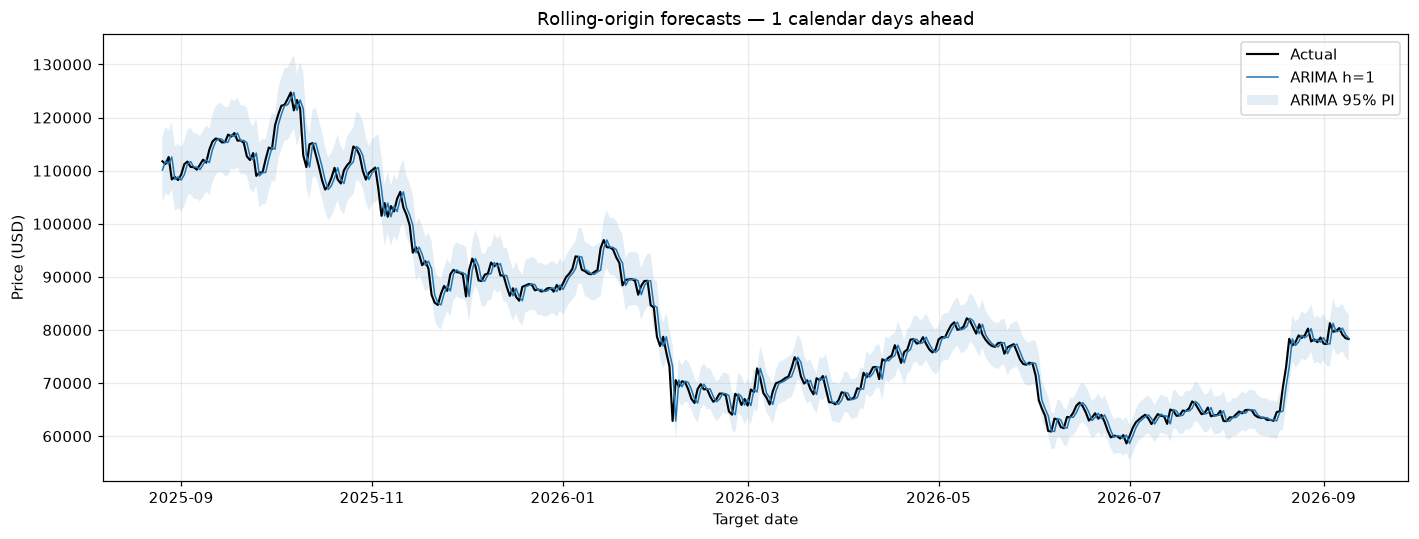

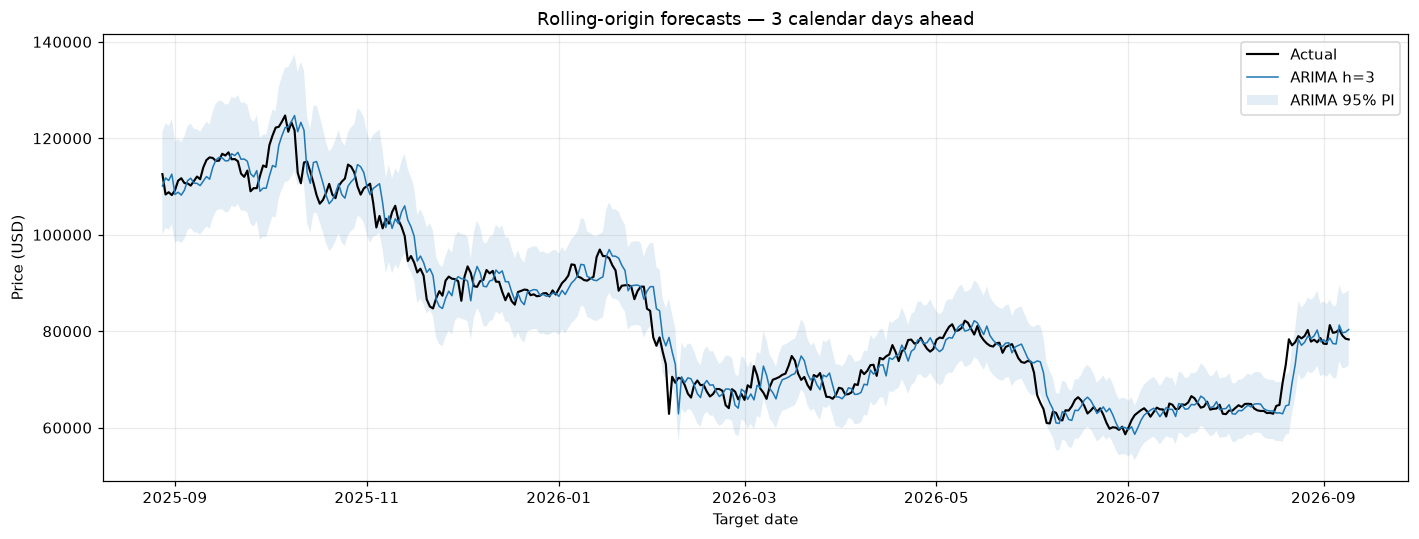

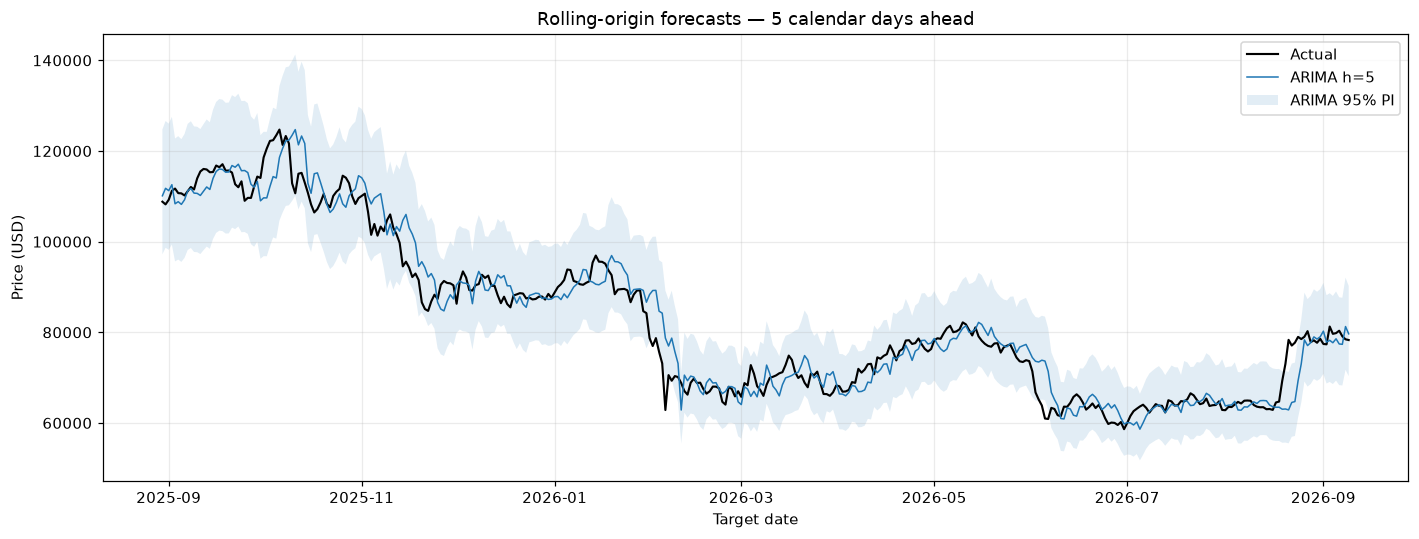

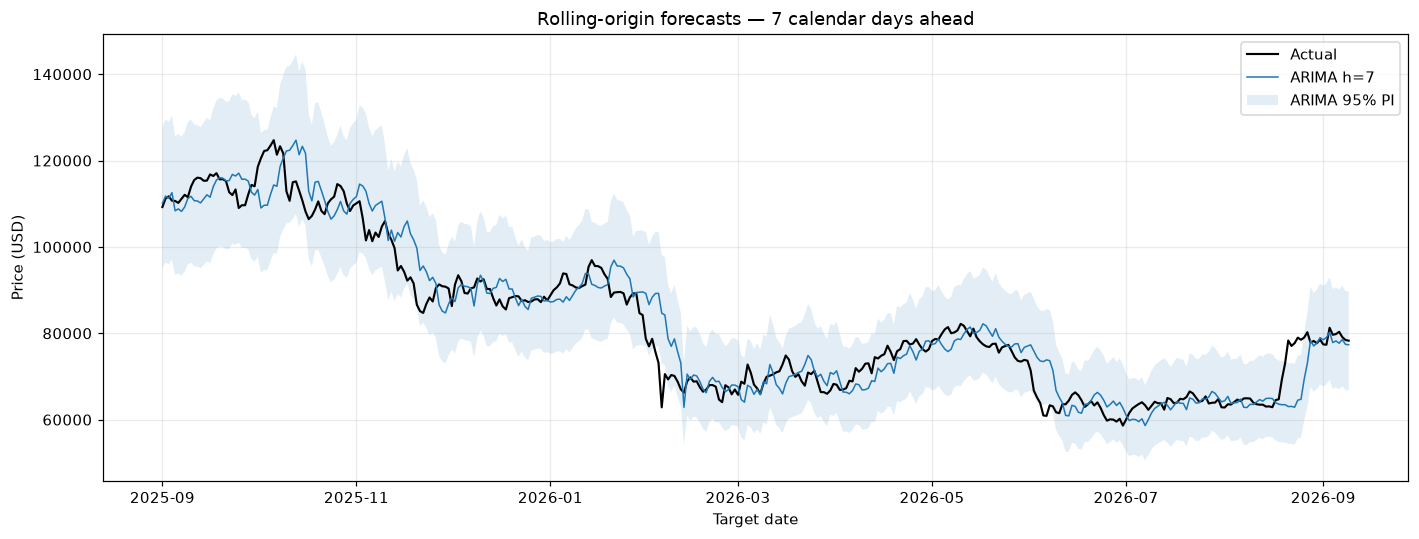

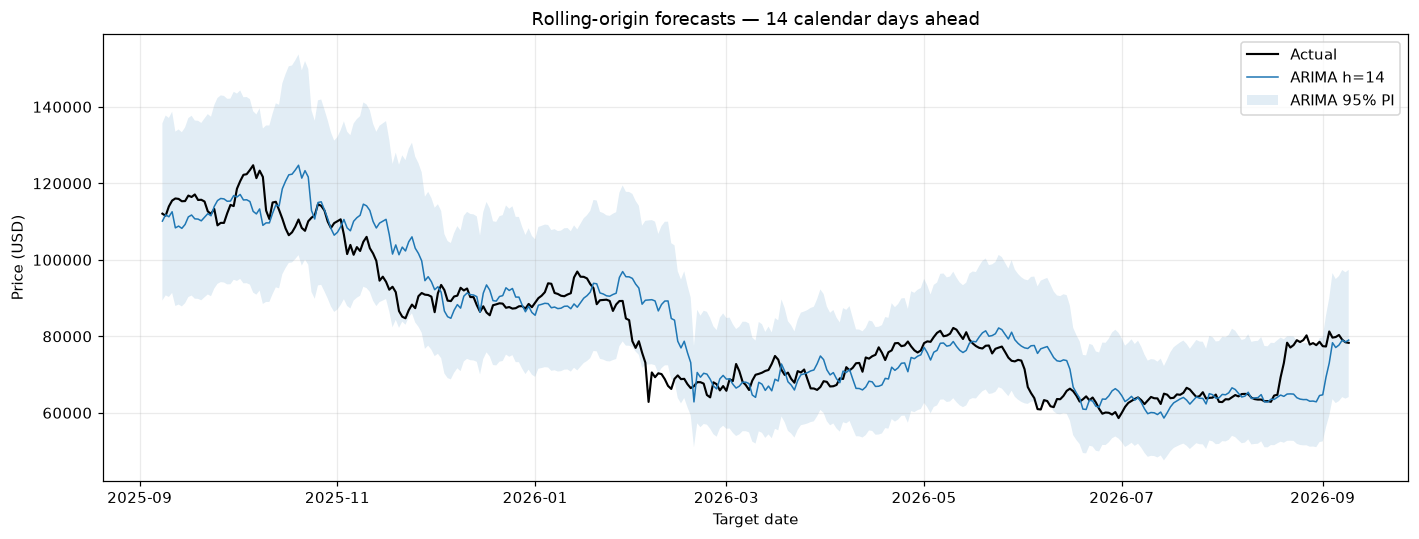

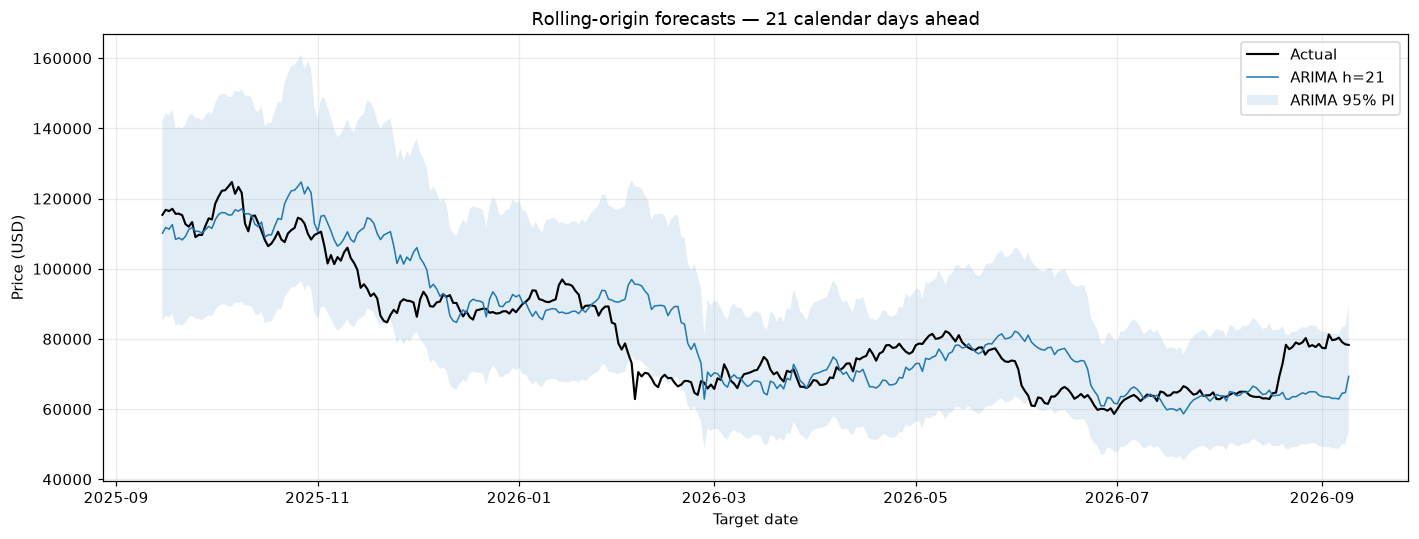

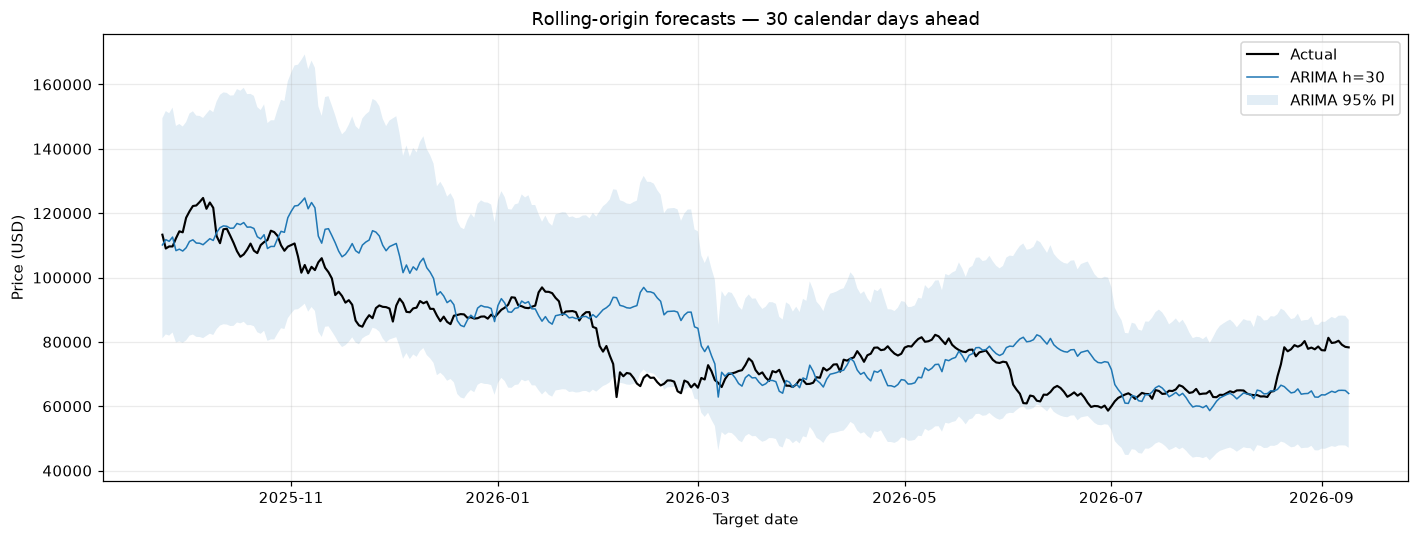

In [14]:
for h, group in forecasts.groupby('h', sort=True):
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(group['target_date'], group['actual'], color='black', label='Actual', linewidth=1.4)
    ax.plot(group['target_date'], group['arima_fc'], label=f'ARIMA h={h}', linewidth=1)
    ax.fill_between(group['target_date'], group['arima_lo95'], group['arima_hi95'], alpha=0.13, label='ARIMA 95% PI')
    ax.set(title=f'Rolling-origin forecasts — {h} calendar days ahead', xlabel='Target date', ylabel='Price (USD)')
    ax.legend()
    save_figure(fig, f'09_forecast_h{h}.png')



### 8.3 Static 30-day forecast from the final train origin

C:\Users\User\AppData\Local\Temp\ipykernel_39008\2645247355.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  static_dates = pd.date_range(train_log.index[-1] + pd.Timedelta(days=1), periods=30, freq='D')


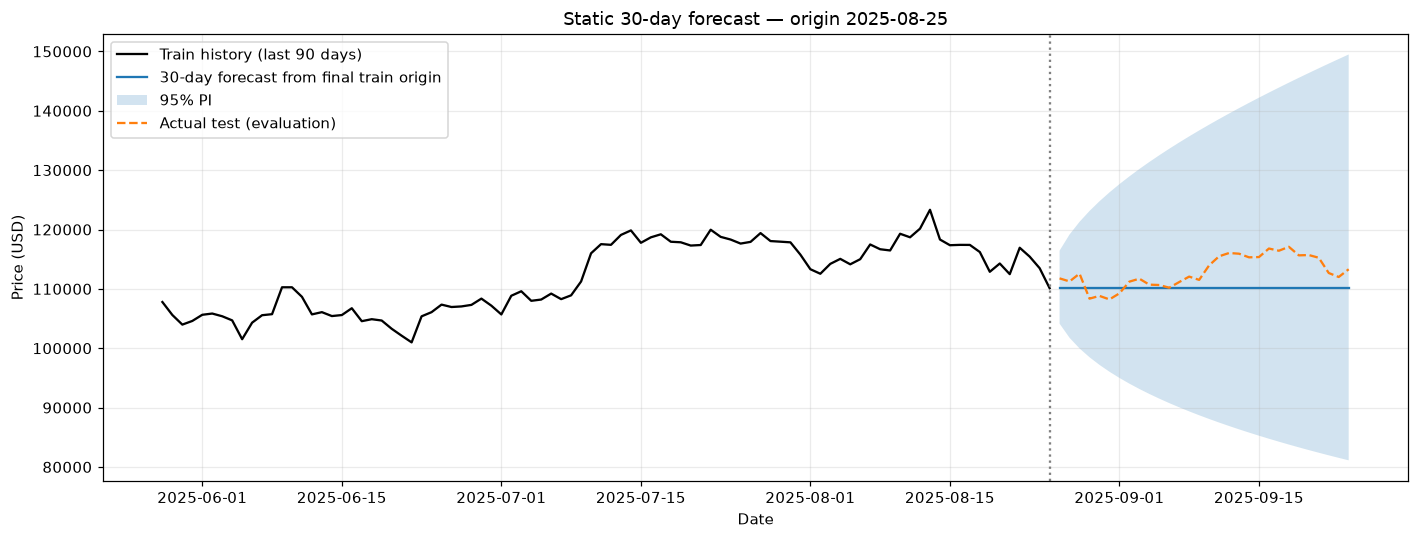

In [15]:
static_fc = res.get_forecast(steps=30)
static_dates = pd.date_range(train_log.index[-1] + pd.Timedelta(days=1), periods=30, freq='D')
static_mean = np.exp(np.asarray(static_fc.predicted_mean))
static_ci = np.exp(np.asarray(static_fc.conf_int(alpha=ALPHA)))
save_table(pd.DataFrame(dict(target_date=static_dates, arima_fc=static_mean,
    arima_lo95=static_ci[:, 0], arima_hi95=static_ci[:, 1])), 'static_30d_forecast.csv')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train_price.iloc[-90:], color='black', label='Train history (last 90 days)')
ax.plot(static_dates, static_mean, label='30-day forecast from final train origin')
ax.fill_between(static_dates, static_ci[:, 0], static_ci[:, 1], alpha=0.2, label='95% PI')
ax.plot(test_price.iloc[:30], linestyle='--', color='tab:orange', label='Actual test (evaluation)')
ax.axvline(train_price.index[-1], color='gray', linestyle=':')
ax.set(title=f'Static 30-day forecast — origin {train_price.index[-1].date()}', ylabel='Price (USD)', xlabel='Date')
ax.legend()
save_figure(fig, '10_static_30d_fan.png')



### 8.4 RMSE and MAPE versus horizon

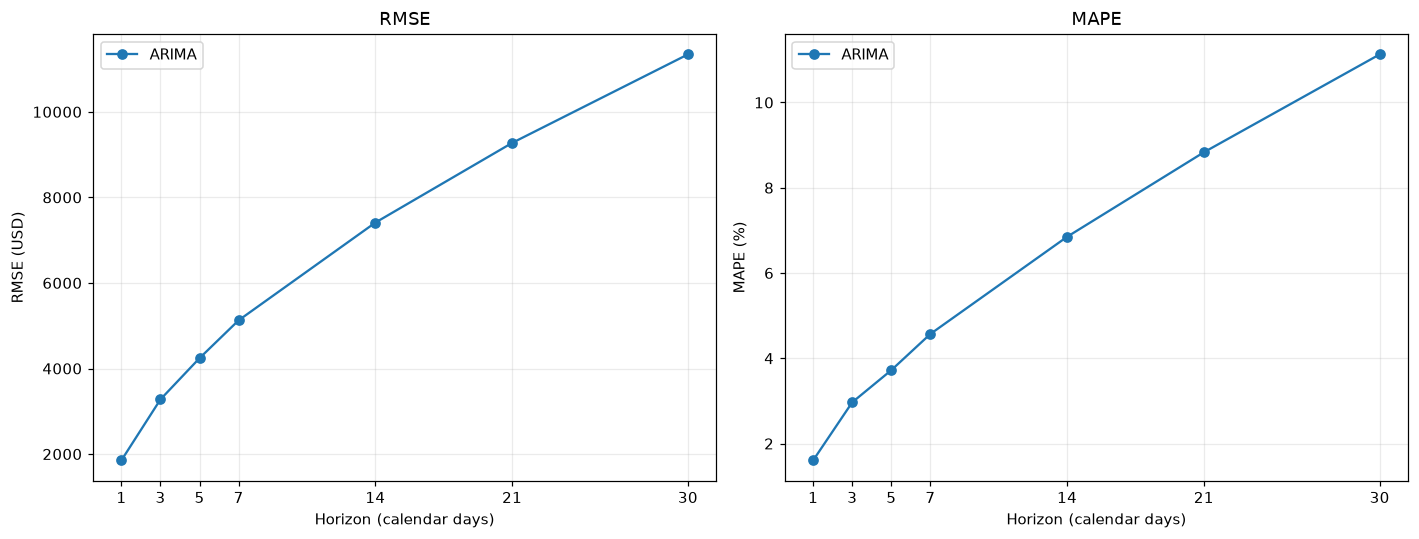

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, unit in zip(axes, ['RMSE', 'MAPE'], ['USD', '%']):
    ax.plot(evaluation['h'], evaluation[metric], marker='o', label='ARIMA')
    ax.set(title=metric, xlabel='Horizon (calendar days)', ylabel=f'{metric} ({unit})', xticks=HORIZONS)
    ax.legend()
save_figure(fig, '11_error_vs_horizon.png')


## Step 9 - Summary and Interpretation
Summarize the selected model, train-only diagnostic evidence, test RMSE and MAPE by horizon, and the future forecast values.
Test metrics measure historical holdout performance. Future forecast rows have no observed target prices yet and are not included in those metrics.


In [17]:
lines = ['### ผลจากการรันจริง', '', f'**d = {d}** — ทดสอบ train เท่านั้น:']
for row in stationarity_tests.itertuples(index=False):
    lines.append(f'- {row.series}, {row.test}: statistic={row.statistic:.5g}, p={row.p_value:.5g}; {row.conclusion}')
lines += ['', f'**โมเดลสุดท้าย:** {final_label}; AIC={res.aic:.3f}, BIC={res.bic:.3f}.',
    'เลือกจาก 3 converged candidates ที่ AIC ต่ำสุด โดยต้องผ่าน Ljung–Box ทุก lag และเงื่อนไขราก',
    '', '**Assumptions (train residuals):**']
for row in assumption_checks.loc[assumption_checks['model'].eq(final_label)].itertuples(index=False):
    p_text = f', p={row.p_value:.5g}' if pd.notna(row.p_value) else ''
    lines.append(f'- {row.test}: **{row.pass_fail}**{p_text}. {row.note}')
lines += ['', 'Mean และ parameter significance รายงานประกอบ; significance ใช้ p < 0.05',
    'หาก normality หรือ ARCH ไม่ผ่าน ช่วงพยากรณ์ 95% อาจให้ coverage ต่ำกว่าหรือสูงกว่าที่ระบุ',
    'Robust standard errors ช่วยการอนุมานพารามิเตอร์ แต่ไม่แก้ volatility dynamics หรือ prediction intervals',
    '', '**ARIMA performance on test:**']
for row in evaluation.itertuples(index=False):
    lines.append(f'- h={row.h}, n={row.n_points}: RMSE={row.RMSE:,.2f} USD; MAPE={row.MAPE:.2f}%.')
lines += ['', 'Lower RMSE and MAPE indicate smaller errors. MAPE is an error percentage, not an accuracy score.',
    'RMSE is measured in USD and penalizes large errors more strongly.',
    'Metrics use actual target prices in the test period only.',
    'Horizons have different sample sizes and overlapping errors; interpret these as descriptive test metrics.',
    '', '**Future forecasts from the latest observed date (fixed train parameters):**']
for row in future_forecasts.itertuples(index=False):
    lines.append(f'- h={row.h}: origin={row.origin_date.date()}, target={row.target_date.date()}, '
                 f'forecast={row.arima_fc:,.2f} USD; 95% PI=[{row.arima_lo95:,.2f}, {row.arima_hi95:,.2f}].')
lines += ['', '**Daily future forecast tables:**',
    *[f'- Next {days} calendar days: `{TABLE_DIR / f"future_forecast_daily_{days}d.csv"}` ({days} consecutive daily rows).' for days in DAILY_FORECAST_WINDOWS]]
lines += ['', 'Future actual prices are not yet available, so these future rows do not have test metrics.',
    'ARIMA(0,1,0) without drift produces flat point forecasts; interval width can still increase with horizon.']
lines += ['', '**ข้อจำกัด:**',
    '- โมเดล univariate ไม่เห็นข่าว นโยบาย ดอกเบี้ย หรือเหตุการณ์ตลาดที่ไม่คาดคิด',
    f'- ช่วง test มีความเปลี่ยนแปลงของระดับราคา/regime: {test_price.min():,.0f}–{test_price.max():,.0f} USD; '
    'ช่วงราคานี้เป็นคำอธิบาย ไม่ใช่ผลทดสอบ structural break',
    '- พารามิเตอร์ตรึงจาก train ตลอดช่วง test; apply(refit=False) อัปเดต state เท่านั้น',
    '- exp(log forecast mean) เป็น median ใน USD; ไม่ได้แก้ lognormal bias',
    '- Volume B 16 แถวเก็บไว้เพื่อ audit และไม่ได้ใช้พยากรณ์',
    '', f'**Outputs:** `{TABLE_DIR}` และ `{FIGURE_DIR}`']
summary_markdown = '\n'.join(lines)
display(Markdown(summary_markdown))
(SUMMARY_DIR / 'summary.md').write_text(summary_markdown, encoding='utf-8')

# Final completeness audit, without additional model fitting.
required_tables = ['split_summary.csv', 'stationarity_tests.csv', 'grid_search_aic_bic.csv',
    'auto_arima_cross_check.csv', 'assumption_checks.csv',
    'forecasts_long.csv', 'evaluation_by_horizon.csv', 'future_forecast_by_horizon.csv',
    *[f'future_forecast_daily_{days}d.csv' for days in DAILY_FORECAST_WINDOWS],
    *[f'forecasts_h{h}.csv' for h in HORIZONS]]
required_figures = ['01_raw_price_volume.png', '02_log_price.png', '03_log_return.png',
    '04_rolling_stats.png', '05_return_distribution.png', '06_train_test_split.png',
    '07_acf_pacf.png', '08_residual_diagnostics.png',
    *[f'09_forecast_h{h}.png' for h in HORIZONS], '10_static_30d_fan.png', '11_error_vs_horizon.png']
assert all((TABLE_DIR / file).is_file() for file in required_tables)
assert all((FIGURE_DIR / file).is_file() for file in required_figures)
assert (SUMMARY_DIR / 'final_model_summary.txt').is_file()
assert (SUMMARY_DIR / 'summary.md').is_file()
assert np.array_equal(np.asarray(res.params), frozen_params)
print('Completed: all required files saved; forecast parameters remained fixed.')


### ผลจากการรันจริง

**d = 1** — ทดสอบ train เท่านั้น:
- log_price, ADF: statistic=-0.37713, p=0.91385; non-stationary (fail to reject H0)
- log_price, KPSS: statistic=3.4073, p=0.01; non-stationary
- diff_log_price, ADF: statistic=-39.628, p=0; stationary
- diff_log_price, KPSS: statistic=0.22723, p=0.1; stationary (fail to reject H0)

**โมเดลสุดท้าย:** ARIMA(0,1,0), trend=n; AIC=-6485.635, BIC=-6480.311.
เลือกจาก 3 converged candidates ที่ AIC ต่ำสุด โดยต้องผ่าน Ljung–Box ทุก lag และเงื่อนไขราก

**Assumptions (train residuals):**
- Ljung-Box lag 10: **PASS**, p=0.10568. model_df=0
- Ljung-Box lag 20: **PASS**, p=0.23754. model_df=0
- Ljung-Box lag 30: **PASS**, p=0.23078. model_df=0
- Mean = 0 (t-test): **PASS**, p=0.28383. Residual mean=0.00078411
- ARCH LM (10 lags): **FAIL**, p=1.6183e-06. 
- Jarque-Bera: **FAIL**, p=4.1198e-181. skew=-0.1801, kurtosis=6.6085
- AR roots outside unit circle: **PASS**. N/A: no roots
- MA roots outside unit circle: **PASS**. N/A: no roots
- Parameter significance: sigma2: **PASS**, p=0. Report only; estimate in statistic column, significance uses p < alpha

Mean และ parameter significance รายงานประกอบ; significance ใช้ p < 0.05
หาก normality หรือ ARCH ไม่ผ่าน ช่วงพยากรณ์ 95% อาจให้ coverage ต่ำกว่าหรือสูงกว่าที่ระบุ
Robust standard errors ช่วยการอนุมานพารามิเตอร์ แต่ไม่แก้ volatility dynamics หรือ prediction intervals

**ARIMA performance on test:**
- h=1, n=380: RMSE=1,853.21 USD; MAPE=1.61%.
- h=3, n=378: RMSE=3,278.08 USD; MAPE=2.97%.
- h=5, n=376: RMSE=4,242.30 USD; MAPE=3.72%.
- h=7, n=374: RMSE=5,126.53 USD; MAPE=4.57%.
- h=14, n=367: RMSE=7,410.70 USD; MAPE=6.85%.
- h=21, n=360: RMSE=9,273.21 USD; MAPE=8.83%.
- h=30, n=351: RMSE=11,342.72 USD; MAPE=11.13%.

Lower RMSE and MAPE indicate smaller errors. MAPE is an error percentage, not an accuracy score.
RMSE is measured in USD and penalizes large errors more strongly.
Metrics use actual target prices in the test period only.
Horizons have different sample sizes and overlapping errors; interpret these as descriptive test metrics.

**Future forecasts from the latest observed date (fixed train parameters):**
- h=1: origin=2026-09-09, target=2026-09-10, forecast=78,297.00 USD; 95% PI=[74,047.36, 82,790.53].
- h=3: origin=2026-09-09, target=2026-09-12, forecast=78,297.00 USD; 95% PI=[71,083.35, 86,242.70].
- h=5: origin=2026-09-09, target=2026-09-14, forecast=78,297.00 USD; 95% PI=[69,111.89, 88,702.83].
- h=7: origin=2026-09-09, target=2026-09-16, forecast=78,297.00 USD; 95% PI=[67,549.77, 90,754.12].
- h=14: origin=2026-09-09, target=2026-09-23, forecast=78,297.00 USD; 95% PI=[63,542.45, 96,477.55].
- h=21: origin=2026-09-09, target=2026-09-30, forecast=78,297.00 USD; 95% PI=[60,629.48, 101,112.86].
- h=30: origin=2026-09-09, target=2026-10-09, forecast=78,297.00 USD; 95% PI=[57,676.85, 106,289.10].

**Daily future forecast tables:**
- Next 7 calendar days: `C:\Users\User\Desktop\PROJECT_2026\OUTPUT\ARIMA_BTC\tables\future_forecast_daily_7d.csv` (7 consecutive daily rows).
- Next 30 calendar days: `C:\Users\User\Desktop\PROJECT_2026\OUTPUT\ARIMA_BTC\tables\future_forecast_daily_30d.csv` (30 consecutive daily rows).

Future actual prices are not yet available, so these future rows do not have test metrics.
ARIMA(0,1,0) without drift produces flat point forecasts; interval width can still increase with horizon.

**ข้อจำกัด:**
- โมเดล univariate ไม่เห็นข่าว นโยบาย ดอกเบี้ย หรือเหตุการณ์ตลาดที่ไม่คาดคิด
- ช่วง test มีความเปลี่ยนแปลงของระดับราคา/regime: 58,631–124,725 USD; ช่วงราคานี้เป็นคำอธิบาย ไม่ใช่ผลทดสอบ structural break
- พารามิเตอร์ตรึงจาก train ตลอดช่วง test; apply(refit=False) อัปเดต state เท่านั้น
- exp(log forecast mean) เป็น median ใน USD; ไม่ได้แก้ lognormal bias
- Volume B 16 แถวเก็บไว้เพื่อ audit และไม่ได้ใช้พยากรณ์

**Outputs:** `C:\Users\User\Desktop\PROJECT_2026\OUTPUT\ARIMA_BTC\tables` และ `C:\Users\User\Desktop\PROJECT_2026\OUTPUT\ARIMA_BTC\figures`

Completed: all required files saved; forecast parameters remained fixed.


### Saved results from the verified execution

### ผลจากการรันจริง

**d = 1** — ทดสอบ train เท่านั้น:
- log_price, ADF: statistic=-0.37713, p=0.91385; non-stationary (fail to reject H0)
- log_price, KPSS: statistic=3.4073, p=0.01; non-stationary
- diff_log_price, ADF: statistic=-39.628, p=0; stationary
- diff_log_price, KPSS: statistic=0.22723, p=0.1; stationary (fail to reject H0)

**โมเดลสุดท้าย:** ARIMA(0,1,0), trend=n; AIC=-6485.635, BIC=-6480.311.
เลือกจาก 3 converged candidates ที่ AIC ต่ำสุด โดยต้องผ่าน Ljung–Box ทุก lag และเงื่อนไขราก

**Assumptions (train residuals):**
- Ljung-Box lag 10: **PASS**, p=0.10568. model_df=0
- Ljung-Box lag 20: **PASS**, p=0.23754. model_df=0
- Ljung-Box lag 30: **PASS**, p=0.23078. model_df=0
- Mean = 0 (t-test): **PASS**, p=0.28383. Residual mean=0.00078411
- ARCH LM (10 lags): **FAIL**, p=1.6183e-06. 
- Jarque-Bera: **FAIL**, p=4.1198e-181. skew=-0.1801, kurtosis=6.6085
- AR roots outside unit circle: **PASS**. N/A: no roots
- MA roots outside unit circle: **PASS**. N/A: no roots
- Parameter significance: sigma2: **PASS**, p=0. Report only; estimate in statistic column, significance uses p < alpha

Mean และ parameter significance รายงานประกอบ; significance ใช้ p < 0.05
หาก normality หรือ ARCH ไม่ผ่าน ช่วงพยากรณ์ 95% อาจให้ coverage ต่ำกว่าหรือสูงกว่าที่ระบุ
Robust standard errors ช่วยการอนุมานพารามิเตอร์ แต่ไม่แก้ volatility dynamics หรือ prediction intervals

**ARIMA performance on test:**
- h=1, n=380: RMSE=1,853.21 USD; MAPE=1.61%.
- h=3, n=378: RMSE=3,278.08 USD; MAPE=2.97%.
- h=5, n=376: RMSE=4,242.30 USD; MAPE=3.72%.
- h=7, n=374: RMSE=5,126.53 USD; MAPE=4.57%.
- h=14, n=367: RMSE=7,410.70 USD; MAPE=6.85%.
- h=21, n=360: RMSE=9,273.21 USD; MAPE=8.83%.
- h=30, n=351: RMSE=11,342.72 USD; MAPE=11.13%.

Lower RMSE and MAPE indicate smaller errors. MAPE is an error percentage, not an accuracy score.
RMSE is measured in USD and penalizes large errors more strongly.
Metrics use actual target prices in the test period only.
Horizons have different sample sizes and overlapping errors; interpret these as descriptive test metrics.

**Future forecasts from the latest observed date (fixed train parameters):**
- h=1: origin=2026-09-09, target=2026-09-10, forecast=78,297.00 USD; 95% PI=[74,047.36, 82,790.53].
- h=3: origin=2026-09-09, target=2026-09-12, forecast=78,297.00 USD; 95% PI=[71,083.35, 86,242.70].
- h=5: origin=2026-09-09, target=2026-09-14, forecast=78,297.00 USD; 95% PI=[69,111.89, 88,702.83].
- h=7: origin=2026-09-09, target=2026-09-16, forecast=78,297.00 USD; 95% PI=[67,549.77, 90,754.12].
- h=14: origin=2026-09-09, target=2026-09-23, forecast=78,297.00 USD; 95% PI=[63,542.45, 96,477.55].
- h=21: origin=2026-09-09, target=2026-09-30, forecast=78,297.00 USD; 95% PI=[60,629.48, 101,112.86].
- h=30: origin=2026-09-09, target=2026-10-09, forecast=78,297.00 USD; 95% PI=[57,676.85, 106,289.10].

Future actual prices are not yet available, so these future rows do not have test metrics.
ARIMA(0,1,0) without drift produces flat point forecasts; interval width can still increase with horizon.

**ข้อจำกัด:**
- โมเดล univariate ไม่เห็นข่าว นโยบาย ดอกเบี้ย หรือเหตุการณ์ตลาดที่ไม่คาดคิด
- ช่วง test มีความเปลี่ยนแปลงของระดับราคา/regime: 58,631–124,725 USD; ช่วงราคานี้เป็นคำอธิบาย ไม่ใช่ผลทดสอบ structural break
- พารามิเตอร์ตรึงจาก train ตลอดช่วง test; apply(refit=False) อัปเดต state เท่านั้น
- exp(log forecast mean) เป็น median ใน USD; ไม่ได้แก้ lognormal bias
- Volume B 16 แถวเก็บไว้เพื่อ audit และไม่ได้ใช้พยากรณ์

**Outputs:** `C:\Users\User\Desktop\PROJECT_2026\OUTPUT\ARIMA_BTC\tables` และ `C:\Users\User\Desktop\PROJECT_2026\OUTPUT\ARIMA_BTC\figures`

### Method references
- [statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html)
- [ARIMAResults.apply — fixed parameters](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.apply.html)
- [pmdarima auto_arima](https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html)
